# German Accident Atlas 2025 — EDA → Severity Baseline → Michael Comparison

**The Random Forest Rangers · Shareable EDA and baseline notebook**

**Business question:** Given that an *injury accident occurs*, estimate the probability that it involves **serious or fatal injury**, conditional on supplied road users, location, time and assumed circumstances.

**Workflow:** Data checks → training-only EDA and visualizations → fixed-rule benchmark from Michael → our training-only smoothed historical scenario-rate baseline → validation comparison.

**Target:** 1 = `UKATEGORIE` 1 or 2; 0 = `UKATEGORIE` 3. We do **not** predict accident occurrence or causal effects. `UART` and `UTYP1` are **descriptive EDA only**, never baseline predictors. Population analysis and advanced models remain in the original research notebook.

**Split:** 70% train / 15% validation / 15% untouched final test. Results and plots are saved from the original notebook and should be regenerated if the source data or environment changes.

**Note:** Michael's fixed decision rule and our probability baseline are different kinds of baselines. Precision/recall comparisons are made on the same validation accidents, but only the scenario-rate model produces meaningful probability estimates.


# German Accident Atlas 2025 — Exploratory Data Analysis

**The Random Forest Rangers | Contributor: Jishnu | Dataset: German Accident Atlas 2025**

**Purpose:** Explore patterns in recorded injury accidents, explain associations with serious/fatal outcomes, and develop evidence-based hypotheses. This notebook contains **EDA plus an initial rule-based severity baseline** (not a trained ML model).

**Confirmed modeling goal:** Binary classification (`0` = slight-injury accident, `1` = serious/fatal accident), with **time/location and explicitly assumed road-user involvement** for hypothetical accident scenarios. Actual collision kind (`UART`) and accident circumstances (`UTYP1`) are not available beforehand. Participant indicators used in the baseline must be understood as specified hypothetical accident characteristics, not predictions of who will actually be involved.

**Group split:** 70% train / 15% validation / 15% test. This notebook examines **training data only** after the split. The shared team's exact split membership must be reconciled before comparing model results across notebooks.

**Reading order:** Data checks → split / target → frequency & timing → descriptive accident characteristics → interactions → geography/spatial EDA → confidence → summary.

**Interpretation:** All severity percentages are *among recorded injury accidents*; they are not the risk that an accident will occur. Associations are not causal.

**Note on earlier notes:** Some narrative percentages reflect the prior exploratory 80/20 split. Re-run all cells and use the newly calculated tables / dynamic summary as authoritative for the 70/15/15 training subset. Review those historical figures before quoting them.


## 1. Load the dataset

Load the German Accident Atlas 2025 CSV. Each row represents one
recorded accident involving injury.

- Use `;` to separate columns and `,` for decimal values.
- Keep accident IDs and location codes as text to preserve leading zeros.
- Check the dataset size and preview the first five rows.

Expected size from earlier checks: 273,007 rows and 25 columns.

In [ ]:
import pandas as pd

# Keep IDs and administrative codes as text.
# This preserves leading zeros, such as state code "01".
string_columns = {
    "UIDENTSTLAE": "string",
    "ULAND": "string",
    "UREGBEZ": "string",
    "UKREIS": "string",
    "UGEMEINDE": "string",
}

accidents = pd.read_csv(
    "data/Unfallorte_2025.csv",
    sep=";",                 # Columns are separated by semicolons
    decimal=",",             # Coordinates use decimal commas
    dtype=string_columns,
    encoding="utf-8-sig",
)

print(f"Rows: {accidents.shape[0]:,}")
print(f"Columns: {accidents.shape[1]}")

accidents.head()

Rows: 273,007
Columns: 25


,UIDENTSTLAE,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,...,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST
0,01250509171013352025,01,0,60,007,2025,5,15,6,3,...,1,0,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1
1,01250405161013752025,01,0,62,053,2025,4,14,7,3,...,0,0,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1
2,01250118171013142025,01,0,56,015,2025,1,9,7,3,...,1,0,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1
3,01250326152013912025,01,0,55,028,2025,3,16,4,3,...,1,1,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1
4,01250225145013362025,01,0,58,116,2025,2,17,3,3,...,0,0,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1


## 2. Check data types and completeness

Check that columns loaded with suitable data types, then count missing
values and duplicates. This helps identify cleaning needs before EDA.

Numeric category codes are labels—not measured quantities.
We inspect the data here without changing it.

In [ ]:
# Show column names, data types and non-missing counts
accidents.info(show_counts=True)

# Count missing values in each column
print("\nMissing values per column:")
print(accidents.isna().sum())

# Check repeated rows and accident IDs
print("\nDuplicate rows:", accidents.duplicated().sum())
print("Duplicate accident IDs:", accidents["UIDENTSTLAE"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   UIDENTSTLAE         273007 non-null  string 
 1   ULAND               273007 non-null  string 
 2   UREGBEZ             273007 non-null  string 
 3   UKREIS              273007 non-null  string 
 4   UGEMEINDE           273007 non-null  string 
 5   UJAHR               273007 non-null  int64  
 6   UMONAT              273007 non-null  int64  
 7   USTUNDE             273007 non-null  int64  
 8   UWOCHENTAG          273007 non-null  int64  
 9   UKATEGORIE          273007 non-null  int64  
 10  UART                273007 non-null  int64  
 11  UTYP1               273007 non-null  int64  
 12  ULICHTVERH          273007 non-null  int64  
 13  IstStrassenzustand  273007 non-null  int64  
 14  IstRad              273007 non-null  int64  
 15  IstPKW              273007 non-null  int64  


### Data-quality summary

Summarise missing values and duplicates in one small table.
Zero missing values means pandas detected no empty entries;
we still need to check whether the recorded codes are valid.

In [ ]:
quality_summary = pd.Series({
    "Rows": len(accidents),
    "Columns": accidents.shape[1],
    "Missing values (all cells)": accidents.isna().sum().sum(),
    "Duplicate rows": accidents.duplicated().sum(),
    "Duplicate accident IDs": accidents["UIDENTSTLAE"].duplicated().sum(),
})

quality_summary.to_frame(name="Count")

,Count
Rows,273007
Columns,25
Missing values (all cells),0
Duplicate rows,0
Duplicate accident IDs,0


## 3. Inspect recorded codes and time values

List the distinct values in time, severity, condition and participant columns.
This helps spot unexpected codes before assigning readable labels.

A value of zero is not automatically missing—it may be a valid category.

In [ ]:
columns_to_check = [
    "ULAND", "UJAHR", "UMONAT", "USTUNDE", "UWOCHENTAG",
    "UKATEGORIE", "UART", "UTYP1", "ULICHTVERH",
    "IstStrassenzustand", "IstRad", "IstPKW", "IstFuss",
    "IstKrad", "IstGkfz", "IstSonstige", "PLST",
]

for column in columns_to_check:
    values = sorted(accidents[column].unique().tolist())
    print(f"{column}: {values}")

ULAND: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16']
UJAHR: [2025]
UMONAT: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
USTUNDE: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
UWOCHENTAG: [1, 2, 3, 4, 5, 6, 7]
UKATEGORIE: [1, 2, 3]
UART: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
UTYP1: [1, 2, 3, 4, 5, 6, 7]
ULICHTVERH: [0, 1, 2]
IstStrassenzustand: [0, 1, 2]
IstRad: [0, 1]
IstPKW: [0, 1]
IstFuss: [0, 1]
IstKrad: [0, 1]
IstGkfz: [0, 1]
IstSonstige: [0, 1]
PLST: [1, 2]


## 4. Add readable labels

Add severity and weekday names using the documentation.
Keep the original columns so the source codes remain available.

Severity describes the accident, not the number of casualties.
Weekday codes start with Sunday = 1.

In [ ]:
severity_labels = {
    1: "Fatal",
    2: "Serious injury",
    3: "Slight injury",
}

weekday_labels = {
    1: "Sunday",
    2: "Monday",
    3: "Tuesday",
    4: "Wednesday",
    5: "Thursday",
    6: "Friday",
    7: "Saturday",
}

# Add labels without replacing the original codes
accidents["severity_label"] = accidents["UKATEGORIE"].map(severity_labels)
accidents["weekday_label"] = accidents["UWOCHENTAG"].map(weekday_labels)

accidents[
    ["UKATEGORIE", "severity_label", "UWOCHENTAG", "weekday_label"]
].head()

,UKATEGORIE,severity_label,UWOCHENTAG,weekday_label
0,3,Slight injury,6,Friday
1,3,Slight injury,7,Saturday
2,3,Slight injury,7,Saturday
3,3,Slight injury,4,Wednesday
4,3,Slight injury,3,Tuesday


## 5. Split: 70% training, 15% validation, 15% test

Our team agreed on a **70/15/15** split. We stratify on the original three severity categories so fatal, serious and slight-injury outcomes are represented in each subset.

**Important:** The procedure below reproduces a local split with `random_state=42`; it does **not** guarantee identical rows to Tiziano's saved `data/splits/` files. Before the group starts model comparisons, verify the shared split row IDs and use those exact assignments. Do not train multiple group models on independently generated partitions.

**EDA policy:** Use **training rows only** for new modeling hypotheses/feature-selection decisions. Validation is for model comparison/threshold tuning and test is held for final evaluation. The complete CSV may be described at a high level for documentation.


In [ ]:
from sklearn.model_selection import train_test_split

# First reserve 30%, then split it equally into validation and test.
train, holdout = train_test_split(
    accidents, test_size=0.30, stratify=accidents["UKATEGORIE"], random_state=42
)
validation, test = train_test_split(
    holdout, test_size=0.50, stratify=holdout["UKATEGORIE"], random_state=42
)

# Only the training portion is explored below.
eda = train.copy()

print(f"Training / EDA: {len(train):,} ({len(train)/len(accidents):.1%})")
print(f"Validation:     {len(validation):,} ({len(validation)/len(accidents):.1%})")
print(f"Test:           {len(test):,} ({len(test)/len(accidents):.1%})")
print("All rows accounted for:", len(train)+len(validation)+len(test)==len(accidents))
print("\nOriginal severity class distributions (%):")
summary = pd.DataFrame({
    "train": train["UKATEGORIE"].value_counts(normalize=True).sort_index()*100,
    "validation": validation["UKATEGORIE"].value_counts(normalize=True).sort_index()*100,
    "test": test["UKATEGORIE"].value_counts(normalize=True).sort_index()*100,
})
display(summary.round(2))


Training / EDA: 191,104 (70.0%)
Validation:     40,951 (15.0%)
Test:           40,952 (15.0%)
All rows accounted for: True

Original severity class distributions (%):


,train,validation,test
UKATEGORIE,,,
1,0.91,0.91,0.91
2,14.81,14.81,14.81
3,84.28,84.28,84.28


### Binary EDA target (matches the agreed model target)

`serious_or_fatal = 1` for `UKATEGORIE` 1 (fatal) or 2 (serious injury), and `0` for category 3 (slight injury). We create this on **training rows only** in this notebook. The original `UKATEGORIE` and all target-derived labels must be excluded from the input features when modeling.


In [ ]:
# Binary target for descriptive EDA; 1 = serious/fatal, 0 = slight
eda["serious_or_fatal"] = eda["UKATEGORIE"].isin([1, 2]).astype(int)
overall_pct = eda["serious_or_fatal"].mean() * 100
print(f"Training-set serious/fatal share: {overall_pct:.2f}%")


Training-set serious/fatal share: 15.72%


## 6. Explore accident severity

Count accidents in each severity category and calculate their percentages
using the development set.

This shows whether the categories are imbalanced, which matters when
choosing a prediction task and evaluation metric.

These are accident counts, not casualty counts.

,Accidents,Percentage
severity_label,,
Fatal,1734,0.91
Serious injury,28301,14.81
Slight injury,161069,84.28


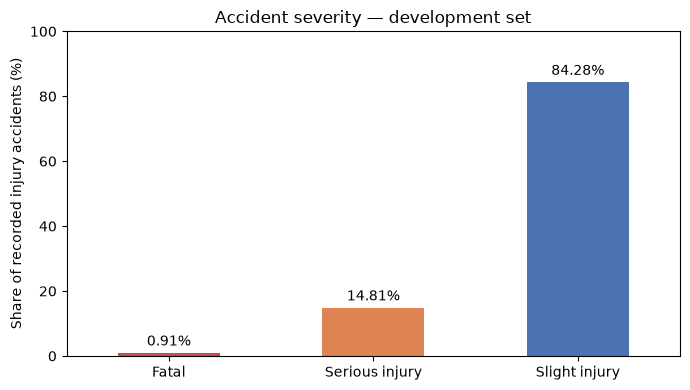

In [ ]:
import matplotlib.pyplot as plt

# Count each severity category in the documented order
severity_summary = (
    eda["severity_label"]
    .value_counts()
    .reindex(["Fatal", "Serious injury", "Slight injury"])
    .to_frame(name="Accidents")
)

severity_summary["Percentage"] = (
    severity_summary["Accidents"] / len(eda) * 100
)

display(severity_summary.round(2))

# Plot percentages to make the imbalance easy to see
ax = severity_summary["Percentage"].plot.bar(
    figsize=(7, 4),
    color=["#c44e52", "#dd8452", "#4c72b0"],
    rot=0,
)

ax.set_title("Accident severity — development set")
ax.set_xlabel("")
ax.set_ylabel("Share of recorded injury accidents (%)")
ax.set_ylim(0, 100)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## 7. Recorded accidents over time

Compare accident counts by month, weekday and hour in the development set.
This reveals seasonal and daily patterns.

Higher counts do not mean higher risk per journey: traffic volumes are
unknown. Month lengths and weekday frequencies also differ.

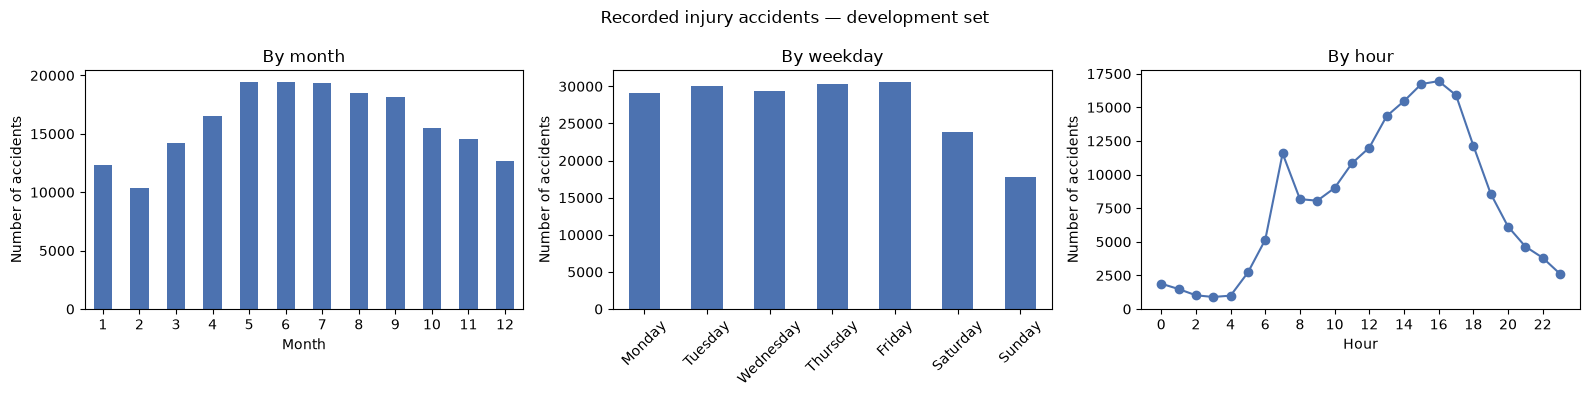

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Months in calendar order
monthly = eda["UMONAT"].value_counts().sort_index()
monthly.plot.bar(ax=axes[0], color="#4c72b0", rot=0)
axes[0].set_title("By month")
axes[0].set_xlabel("Month")

# Weekdays in Monday-to-Sunday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]
weekly = eda["weekday_label"].value_counts().reindex(weekday_order)
weekly.plot.bar(ax=axes[1], color="#4c72b0", rot=45)
axes[1].set_title("By weekday")
axes[1].set_xlabel("")

# Hours in chronological order
hourly = eda["USTUNDE"].value_counts().sort_index()
hourly.plot(ax=axes[2], marker="o", color="#4c72b0")
axes[2].set_title("By hour")
axes[2].set_xlabel("Hour")
axes[2].set_xticks(range(0, 24, 2))

for ax in axes:
    ax.set_ylabel("Number of accidents")
    ax.set_ylim(bottom=0)

fig.suptitle("Recorded injury accidents — development set")
plt.tight_layout()
plt.show()

### Finding: accident counts vary over time

- May–July have higher counts; February has the lowest.
- Weekdays have more recorded accidents than weekends.
- Counts peak around 16:00, with a smaller peak around 07:00.
- These patterns describe accident frequency, not risk per journey.

## 8. Monthly accident severity

We compare the number of accidents and the percentage of serious/fatal accidents across all 12 months.

**Hypothesis:** Accident severity may vary seasonally due to weather, daylight, and changing traffic conditions.

In [ ]:

# Check monthly values
print(eda["UMONAT"].value_counts(dropna=False).sort_index())

# Calculate severity by month
monthly_severity = eda.groupby("UMONAT").agg(
    accidents=("UKATEGORIE", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_share=("serious_or_fatal", "mean")
)

# Convert to percentage
monthly_severity["serious_fatal_pct"] = (
    monthly_severity["serious_fatal_share"] * 100
)

# Display months in chronological order
display(
    monthly_severity[
        ["accidents", "serious_fatal_count", "serious_fatal_pct"]
    ].round(2)
)


UMONAT
1     12332
2     10394
3     14197
4     16567
5     19414
6     19462
7     19329
8     18500
9     18127
10    15524
11    14549
12    12709
Name: count, dtype: int64


,accidents,serious_fatal_count,serious_fatal_pct
UMONAT,,,
1,12332,1767,14.33
2,10394,1496,14.39
3,14197,2300,16.20
4,16567,2743,16.56
5,19414,3186,16.41
6,19462,3311,17.01
7,19329,3109,16.08
8,18500,3327,17.98
9,18127,2833,15.63


### Visualization — Monthly Accident Severity

We visualize the serious/fatal accident percentage across the 12 months.

The dashed line represents the overall average (15.72%).

This helps us identify seasonal patterns and months with unusually high or low severity proportions.

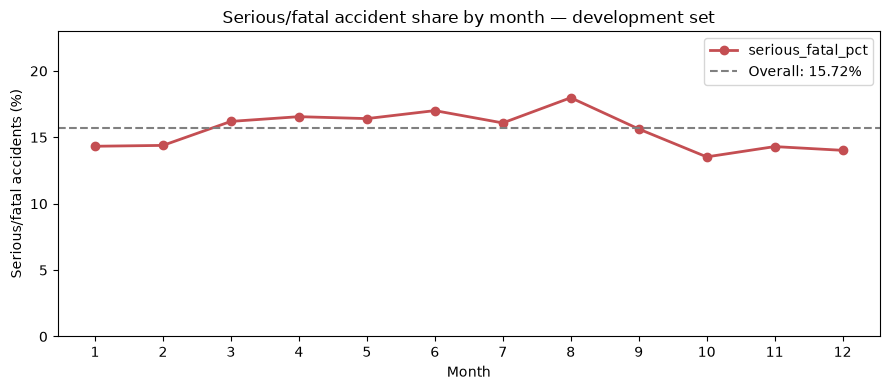

In [ ]:

# Plot monthly accident severity
ax = monthly_severity["serious_fatal_pct"].plot(
    kind="line",
    figsize=(9, 4),
    marker="o",
    linewidth=2,
    color="#c44e52"
)

# Add overall average
ax.axhline(
    overall_pct,
    color="grey",
    linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

# Format chart
ax.set_title("Serious/fatal accident share by month — development set")
ax.set_xlabel("Month")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_xticks(range(1, 13))
ax.set_ylim(0, monthly_severity["serious_fatal_pct"].max() + 5)

ax.legend()
plt.tight_layout()
plt.show()


## 9. Weekday accident severity

Calculate the serious/fatal share of recorded injury accidents for
each weekday. Include counts to distinguish frequency from severity.

,accidents,serious_fatal_count,serious_fatal_pct
weekday_label,,,
Monday,29088,4132,14.21
Tuesday,29999,4280,14.27
Wednesday,29316,4368,14.90
Thursday,30347,4662,15.36
Friday,30629,4770,15.57
Saturday,23914,4292,17.95
Sunday,17811,3531,19.82


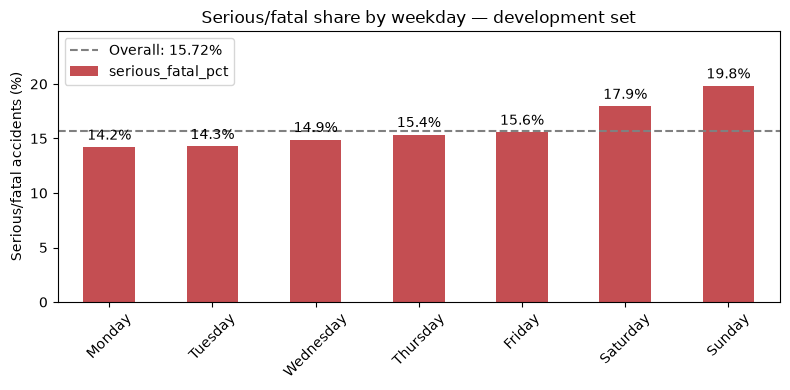

In [ ]:
weekday_severity = (
    eda.groupby("weekday_label")
    .agg(
        accidents=("UKATEGORIE", "size"),
        serious_fatal_count=("serious_or_fatal", "sum"),
        serious_fatal_share=("serious_or_fatal", "mean"),
    )
    .reindex(weekday_order)
)

weekday_severity["serious_fatal_pct"] = (
    weekday_severity["serious_fatal_share"] * 100
)

display(weekday_severity[
    ["accidents", "serious_fatal_count", "serious_fatal_pct"]
].round(2))

ax = weekday_severity["serious_fatal_pct"].plot.bar(
    figsize=(8, 4), color="#c44e52", rot=45
)

ax.axhline(
    overall_pct, color="grey", linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)
ax.set_title("Serious/fatal share by weekday — development set")
ax.set_xlabel("")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_ylim(0, weekday_severity["serious_fatal_pct"].max() + 5)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.legend()

plt.tight_layout()
plt.show()

## 10. Hourly accident severity

For each hour, calculate the percentage of recorded injury accidents
that involved serious injury or death.

This separates accident volume from severity:
an hour can have fewer accidents but a higher serious/fatal share.
Combining these categories here is for exploration, not a final target choice.

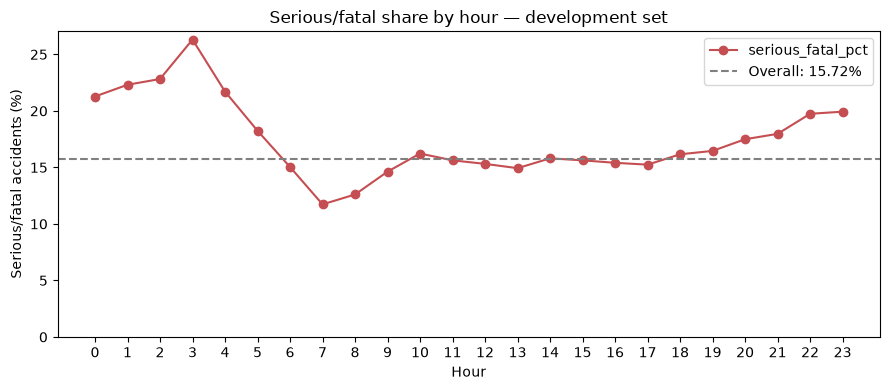

,accidents,serious_fatal_count,serious_fatal_pct
USTUNDE,,,
0,1885,401,21.27
1,1488,332,22.31
2,1021,233,22.82
3,897,236,26.31
4,995,216,21.71
5,2719,496,18.24
6,5153,775,15.04
7,11569,1357,11.73
8,8172,1030,12.60


In [ ]:
hourly_severity = eda.groupby("USTUNDE").agg(
    accidents=("UKATEGORIE", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_share=("serious_or_fatal", "mean"),
)

# The mean of True/False values gives the proportion
hourly_severity["serious_fatal_pct"] = (
    hourly_severity["serious_fatal_share"] * 100
)

ax = hourly_severity["serious_fatal_pct"].plot(
    figsize=(9, 4), marker="o", color="#c44e52"
)

ax.axhline(
    overall_pct, color="grey", linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

ax.set_title("Serious/fatal share by hour — development set")
ax.set_xlabel("Hour")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_xticks(range(24))
ax.set_ylim(bottom=0)
ax.legend()

plt.tight_layout()
plt.show()

# Keep counts visible when interpreting percentages
display(hourly_severity[
    ["accidents", "serious_fatal_count", "serious_fatal_pct"]
].round(2))

## 11. Lighting conditions

Compare serious/fatal shares in daylight, twilight and darkness.
The documented codes are 0 = daylight, 1 = twilight, 2 = darkness.

This shows an association; it does not isolate the effect of lighting
from time, location or participant differences.

,accidents,serious_fatal_count,serious_fatal_pct
ULICHTVERH,,,
Daylight,145722,22340,15.33
Twilight,9765,1525,15.62
Darkness,35617,6170,17.32


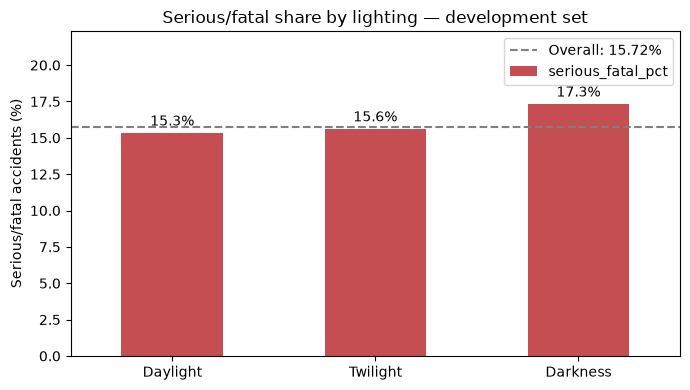

In [ ]:
light_labels = {0: "Daylight", 1: "Twilight", 2: "Darkness"}

lighting_severity = eda.groupby("ULICHTVERH").agg(
    accidents=("UKATEGORIE", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_share=("serious_or_fatal", "mean"),
)

lighting_severity["serious_fatal_pct"] = (
    lighting_severity["serious_fatal_share"] * 100
)
lighting_severity = lighting_severity.rename(index=light_labels)

display(lighting_severity[
    ["accidents", "serious_fatal_count", "serious_fatal_pct"]
].round(2))

ax = lighting_severity["serious_fatal_pct"].plot.bar(
    figsize=(7, 4), color="#c44e52", rot=0
)

ax.axhline(
    overall_pct, color="grey", linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)
ax.set_title("Serious/fatal share by lighting — development set")
ax.set_xlabel("")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_ylim(0, lighting_severity["serious_fatal_pct"].max() + 5)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.legend()

plt.tight_layout()
plt.show()

## 12. Road-surface conditions

Compare serious/fatal shares on dry, wet/damp/slippery and winter-slippery
surfaces. Include counts because the groups may differ greatly in size.

These percentages describe severity among recorded injury accidents,
not the likelihood of having an accident on each surface.

,accidents,serious_fatal_count,serious_fatal_pct
IstStrassenzustand,,,
Dry,148923,23832,16.00
Wet/damp/slippery,38385,5637,14.69
Winter-slippery,3796,566,14.91


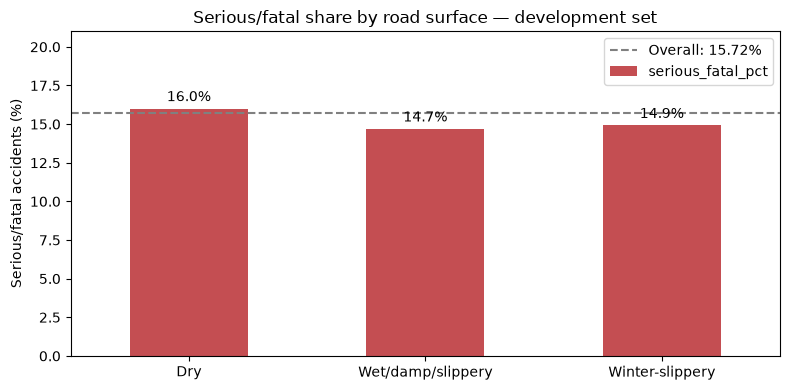

In [ ]:
road_labels = {
    0: "Dry",
    1: "Wet/damp/slippery",
    2: "Winter-slippery",
}

road_severity = eda.groupby("IstStrassenzustand").agg(
    accidents=("UKATEGORIE", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_share=("serious_or_fatal", "mean"),
)

road_severity["serious_fatal_pct"] = (
    road_severity["serious_fatal_share"] * 100
)
road_severity = road_severity.rename(index=road_labels)

display(road_severity[
    ["accidents", "serious_fatal_count", "serious_fatal_pct"]
].round(2))

ax = road_severity["serious_fatal_pct"].plot.bar(
    figsize=(8, 4), color="#c44e52", rot=0
)

ax.axhline(
    overall_pct, color="grey", linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)
ax.set_title("Serious/fatal share by road surface — development set")
ax.set_xlabel("")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_ylim(0, road_severity["serious_fatal_pct"].max() + 5)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.legend()

plt.tight_layout()
plt.show()

## 13. Accident type (`UART`)

We investigate whether accident type (`UART`) is associated with serious or fatal outcomes.

We compare the severity percentage across accident categories to identify potentially useful predictive information.

Only the development dataset is used.

In [ ]:

# Check available accident types
eda["UART"].value_counts(dropna=False).sort_index()


UART
0    35145
1    10482
2    29759
3    10667
4    13392
5    50875
6    14808
7     2075
8    14931
9     8970
Name: count, dtype: int64

### Severity Comparison by Accident Type

We calculate the percentage of serious/fatal accidents for each accident type (`UART`).

**Goal:** Identify whether some accident types have substantially higher severity rates than others.

We compare each category against the overall average of 15.72%.

In [ ]:

# Calculate severity by accident type
type_severity = eda.groupby("UART").agg(
    accidents=("UKATEGORIE", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_share=("serious_or_fatal", "mean")
)

# Convert to percentages
type_severity["serious_fatal_pct"] = (
    type_severity["serious_fatal_share"] * 100
)

# Show categories sorted by severity
display(
    type_severity[
        ["accidents", "serious_fatal_count", "serious_fatal_pct"]
    ].sort_values("serious_fatal_pct", ascending=False).round(2)
)


,accidents,serious_fatal_count,serious_fatal_pct
UART,,,
8,14931,3994,26.75
9,8970,2350,26.20
4,13392,3267,24.40
6,14808,2940,19.85
7,2075,350,16.87
0,35145,5884,16.74
5,50875,6564,12.90
3,10667,1353,12.68
1,10482,981,9.36


### Visualization — Accident Type and Severity

We visualize the percentage of serious/fatal accidents for each accident type (`UART`).

The categories are currently shown by their code values (0–9), sorted from highest to lowest severity.

This helps us see whether accident type may be a useful predictor of accident severity.

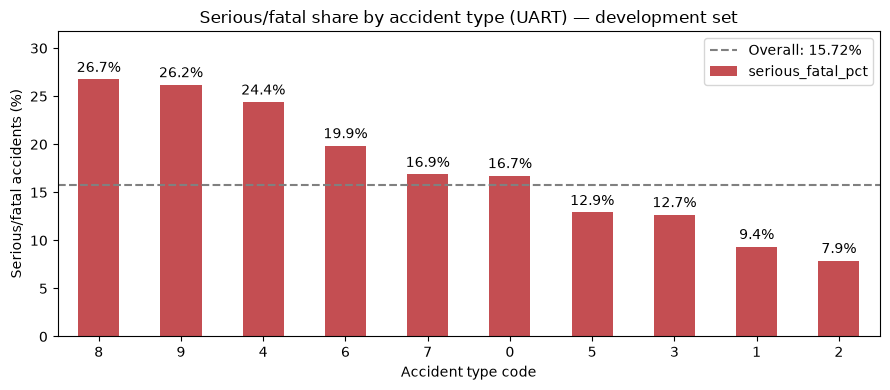

In [ ]:
# Sort accident types by severity percentage
type_severity_sorted = type_severity.sort_values(
    "serious_fatal_pct", ascending=False
)

# Plot serious/fatal percentage by accident type
ax = type_severity_sorted["serious_fatal_pct"].plot.bar(
    figsize=(9, 4),
    color="#c44e52",
    rot=0
)

# Add overall average line
ax.axhline(
    overall_pct,
    color="grey",
    linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

ax.set_title("Serious/fatal share by accident type (UART) — development set")
ax.set_xlabel("Accident type code")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_ylim(0, type_severity_sorted["serious_fatal_pct"].max() + 5)

# Add percentage labels above bars
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.legend()
plt.tight_layout()
plt.show()

## 14. Accident circumstances (`UTYP1`)

**Question:** Are certain accident circumstances associated with more serious or fatal outcomes?

**Hypothesis:** Different traffic situations may have different accident severity proportions.

We investigate `UTYP1` using the development dataset and compare each category with the overall severity average.

In [ ]:

# Check available accident circumstance categories
eda["UTYP1"].value_counts(dropna=False).sort_index()


UTYP1
1    38608
2    24903
3    40633
4     7715
5     6612
6    44925
7    27708
Name: count, dtype: int64

### Severity Comparison by Accident Circumstances

We calculate the percentage of serious/fatal accidents for each `UTYP1` category.

**Goal:** Identify whether certain accident circumstances are associated with more severe outcomes.

We compare each category against the overall average of 15.72%.

In [ ]:

# Calculate severity for each accident circumstance
utyp_severity = eda.groupby("UTYP1").agg(
    accidents=("UKATEGORIE", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_share=("serious_or_fatal", "mean")
)

# Convert proportion to percentage
utyp_severity["serious_fatal_pct"] = (
    utyp_severity["serious_fatal_share"] * 100
)

# Sort from highest to lowest severity
utyp_severity = utyp_severity.sort_values(
    "serious_fatal_pct", ascending=False
)

display(
    utyp_severity[
        ["accidents", "serious_fatal_count", "serious_fatal_pct"]
    ].round(2)
)


,accidents,serious_fatal_count,serious_fatal_pct
UTYP1,,,
1,38608,9058,23.46
4,7715,1800,23.33
7,27708,4620,16.67
2,24903,3320,13.33
3,40633,5182,12.75
6,44925,5371,11.96
5,6612,684,10.34


### Visualization — Accident Circumstances and Severity

We compare the percentage of serious/fatal accidents across the seven `UTYP1` categories.

The dashed line represents the overall average (15.72%).

This helps identify which accident circumstances are associated with higher severity proportions.

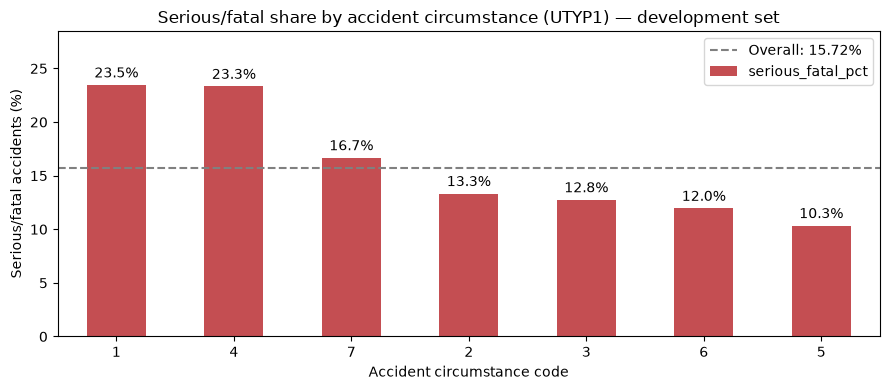

In [ ]:

# Plot severity by accident circumstance
ax = utyp_severity["serious_fatal_pct"].plot.bar(
    figsize=(9, 4),
    color="#c44e52",
    rot=0
)

# Add overall average
ax.axhline(
    overall_pct,
    color="grey",
    linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

ax.set_title("Serious/fatal share by accident circumstance (UTYP1) — development set")
ax.set_xlabel("Accident circumstance code")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_ylim(0, utyp_severity["serious_fatal_pct"].max() + 5)

# Add percentage labels
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.legend()
plt.tight_layout()
plt.show()


## 15. Road-user involvement

**Question:** Do accidents involving different road users have different serious/fatal injury rates?

**Hypothesis:** Accidents involving vulnerable road users, such as pedestrians, cyclists, and motorcyclists, may have higher severity proportions.

We compare severity percentages across road-user categories using the development dataset.

In [ ]:

# Find road-user columns in the dataset
[col for col in eda.columns if col.lower().startswith("ist")]


['IstStrassenzustand',
 'IstRad',
 'IstPKW',
 'IstFuss',
 'IstKrad',
 'IstGkfz',
 'IstSonstige']

### Checking Road-User Indicators

Each road-user column indicates whether a particular road-user type was involved in the accident.

We check the values before comparing accident severity.

- `0` = Not involved
- `1` = Involved

An accident can involve multiple road-user types, so the categories may overlap.

In [ ]:

# Select road-user columns
road_users = [
    "IstRad",
    "IstPKW",
    "IstFuss",
    "IstKrad",
    "IstGkfz",
    "IstSonstige"
]

# Check values and missing data
for col in road_users:
    print(f"\n{col}")
    print(eda[col].value_counts(dropna=False))



IstRad
IstRad
0    128453
1     62651
Name: count, dtype: int64

IstPKW
IstPKW
1    138226
0     52878
Name: count, dtype: int64

IstFuss
IstFuss
0    174197
1     16907
Name: count, dtype: int64

IstKrad
IstKrad
0    165311
1     25793
Name: count, dtype: int64

IstGkfz
IstGkfz
0    183446
1      7658
Name: count, dtype: int64

IstSonstige
IstSonstige
0    163440
1     27664
Name: count, dtype: int64


### Severity Comparison by Road User

We calculate the percentage of serious/fatal accidents involving each road-user type.

**Goal:** Identify whether accidents involving pedestrians, cyclists, motorcycles, or other vehicles have different severity rates.

**Note:** Categories can overlap because one accident may involve multiple road-user types.

In [ ]:

# Readable labels for road users
road_user_labels = {
    "IstRad": "Bicycle",
    "IstPKW": "Car",
    "IstFuss": "Pedestrian",
    "IstKrad": "Motorcycle",
    "IstGkfz": "Goods vehicle",
    "IstSonstige": "Other"
}

# Calculate severity for accidents involving each road-user type
road_user_results = []

for col in road_users:
    involved = eda[eda[col] == 1]

    road_user_results.append({
        "road_user": road_user_labels[col],
        "accidents": len(involved),
        "serious_fatal_count": involved["serious_or_fatal"].sum(),
        "serious_fatal_pct": involved["serious_or_fatal"].mean() * 100
    })

# Convert results into a DataFrame
road_user_severity = pd.DataFrame(road_user_results)

# Sort from highest to lowest severity
road_user_severity = road_user_severity.sort_values(
    "serious_fatal_pct", ascending=False
)

display(road_user_severity.round(2))


,road_user,accidents,serious_fatal_count,serious_fatal_pct
3,Motorcycle,25793,6415,24.87
4,Goods vehicle,7658,1612,21.05
2,Pedestrian,16907,3242,19.18
0,Bicycle,62651,9402,15.01
5,Other,27664,3962,14.32
1,Car,138226,19011,13.75


### Visualization — Road Users and Accident Severity

We compare the serious/fatal accident percentage for each road-user category.

The dashed line represents the overall severity average (15.72%).

This helps identify which road-user involvement indicators may be useful for predicting accident severity.

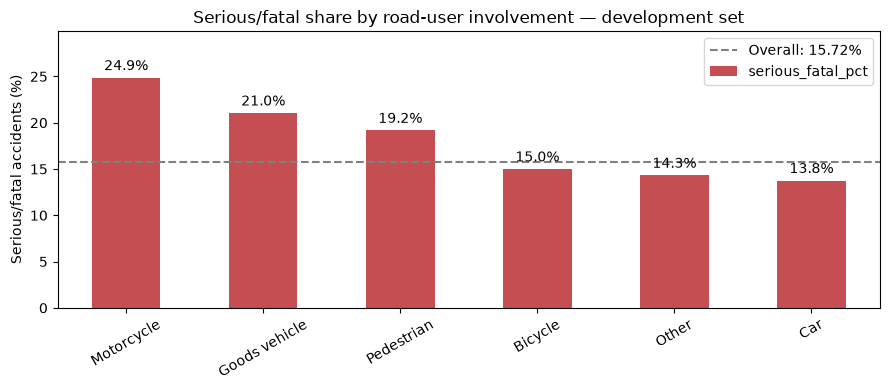

In [ ]:

# Plot severity percentage by road-user involvement
ax = road_user_severity.plot.bar(
    x="road_user",
    y="serious_fatal_pct",
    figsize=(9, 4),
    color="#c44e52",
    rot=30,
    legend=False
)

# Overall average
ax.axhline(
    overall_pct,
    color="grey",
    linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

ax.set_title("Serious/fatal share by road-user involvement — development set")
ax.set_xlabel("")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_ylim(0, road_user_severity["serious_fatal_pct"].max() + 5)

# Show percentages above bars
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.legend()
plt.tight_layout()
plt.show()


## 16. Weekday × hour

We combine weekday and hour to investigate when serious/fatal accidents are proportionally more common.

**Hypothesis:** Weekend nights may have higher severity proportions than weekday daytime hours.

We use a heatmap to identify patterns that individual analyses might miss.

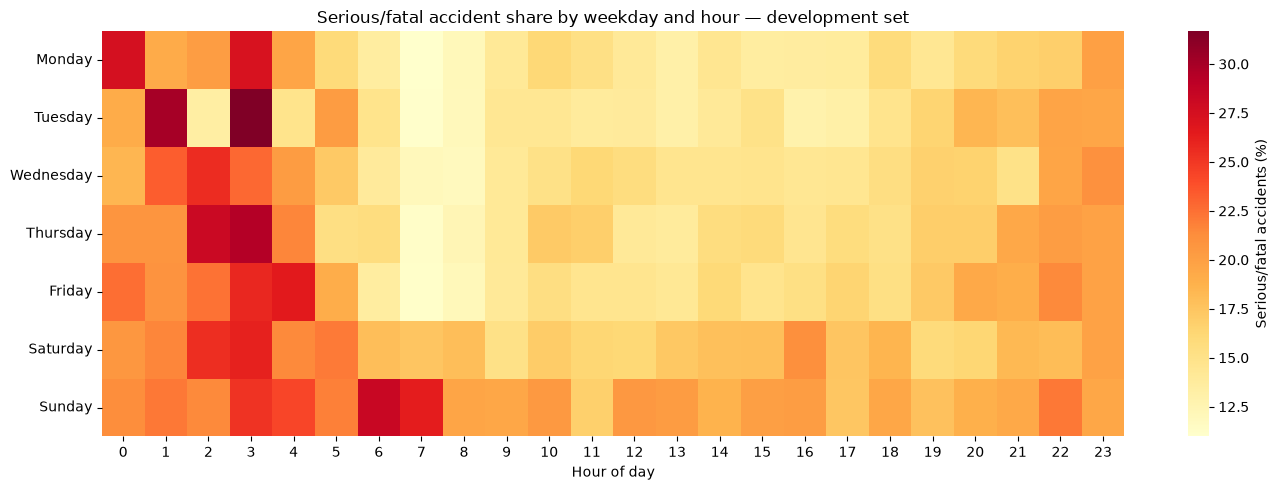

In [ ]:
import seaborn as sns
# Calculate severity percentage for each weekday and hour
weekday_hour = eda.pivot_table(
    index="UWOCHENTAG",
    columns="USTUNDE",
    values="serious_or_fatal",
    aggfunc="mean"
) * 100

# Label weekdays
weekday_hour.index = weekday_hour.index.map(weekday_labels)

# Arrange days from Monday to Sunday
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_hour = weekday_hour.reindex(weekday_order)

# Visualize using a heatmap
plt.figure(figsize=(14, 5))

sns.heatmap(
    weekday_hour,
    cmap="YlOrRd",
    annot=False,
    cbar_kws={"label": "Serious/fatal accidents (%)"}
)

plt.title("Serious/fatal accident share by weekday and hour — development set")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.tight_layout()
plt.show()


### Checking Sample Sizes — Weekday × Hour

Some weekday-hour combinations may have relatively few recorded accidents.

We check the number of accidents in each combination to avoid overinterpreting unusually high severity percentages.

In [ ]:

# Count accidents for each weekday-hour combination
weekday_hour_counts = eda.pivot_table(
    index="UWOCHENTAG",
    columns="USTUNDE",
    values="UKATEGORIE",
    aggfunc="size"
)

# Apply weekday labels and order
weekday_hour_counts.index = weekday_hour_counts.index.map(weekday_labels)
weekday_hour_counts = weekday_hour_counts.reindex(weekday_order)

# Summarize sample sizes
print("Minimum accidents in a cell:", weekday_hour_counts.min().min())
print("Maximum accidents in a cell:", weekday_hour_counts.max().max())

# Show combinations with fewer than 100 accidents
display(weekday_hour_counts.where(weekday_hour_counts < 100).dropna(how="all").dropna(axis=1, how="all"))


Minimum accidents in a cell: 60
Maximum accidents in a cell: 2967


USTUNDE,2,3
UWOCHENTAG,,
Monday,84.0,66.0
Tuesday,67.0,60.0
Wednesday,90.0,79.0
Thursday,71.0,85.0
Friday,NaN,97.0


### EDA Insight — Weekday × Hour

- Late-night and early-morning accidents generally show higher serious/fatal proportions.
- Sunday mornings show elevated severity compared with weekday mornings.
- Weekday commuting hours generally have lower severity proportions.
- Six weekday-hour combinations contain fewer than 100 accidents, making their percentages less stable.
- Weekday and hour may provide useful information together for predicting accident severity.

## 17. Road user × time of day

We investigate whether serious/fatal accident proportions differ by road-user involvement and time of day.

**Hypothesis:** Accidents involving certain road users may have higher severity proportions during nighttime hours.

We divide the day into four periods and use only the development dataset.

In [ ]:

# Create a copy for this analysis
eda_time = eda.copy()

# Define four time periods
def get_time_period(hour):
    if 0 <= hour < 6:
        return "Night (00–05)"
    elif 6 <= hour < 12:
        return "Morning (06–11)"
    elif 12 <= hour < 18:
        return "Afternoon (12–17)"
    else:
        return "Evening (18–23)"

# Create a new feature
eda_time["time_period"] = eda_time["USTUNDE"].apply(get_time_period)

# Check accident counts
eda_time["time_period"].value_counts()


time_period
Afternoon (12–17)    91388
Morning (06–11)      52787
Evening (18–23)      37924
Night (00–05)         9005
Name: count, dtype: int64

### Severity by Road User and Time Period

We calculate the percentage of serious/fatal accidents for each combination of road-user involvement and time period.

This helps identify whether the relationship between road-user involvement and accident severity changes throughout the day.

Road-user groups can overlap because an accident may involve multiple types.

In [ ]:

# Calculate severity for each road-user and time-period combination
results = []

for col in road_users:
    involved = eda_time[eda_time[col] == 1]

    for period, group in involved.groupby("time_period"):
        results.append({
            "road_user": road_user_labels[col],
            "time_period": period,
            "accidents": len(group),
            "serious_fatal_pct": group["serious_or_fatal"].mean() * 100
        })

# Create a DataFrame
road_time_severity = pd.DataFrame(results)

# Define chronological order
period_order = [
    "Night (00–05)",
    "Morning (06–11)",
    "Afternoon (12–17)",
    "Evening (18–23)"
]

# Create a comparison table
road_time_table = road_time_severity.pivot(
    index="road_user",
    columns="time_period",
    values="serious_fatal_pct"
).reindex(columns=period_order)

display(road_time_table.round(2))


time_period,Night (00–05),Morning (06–11),Afternoon (12–17),Evening (18–23)
road_user,,,,
Bicycle,21.24,13.30,14.91,16.79
Car,20.24,12.80,13.18,15.06
Goods vehicle,27.88,20.26,20.08,23.47
Motorcycle,26.72,21.52,25.54,26.31
Other,19.15,13.53,13.94,15.22
Pedestrian,27.41,18.87,18.52,20.06


### Sample Size Check — Road Users × Time

We check how many recorded accidents belong to each road-user and time-period combination.

Smaller groups may produce less reliable severity percentages.

In [ ]:

# Create a table of accident counts
road_time_counts = road_time_severity.pivot(
    index="road_user",
    columns="time_period",
    values="accidents"
).reindex(columns=period_order)

display(road_time_counts)

print("Smallest group:", road_time_counts.min().min())


time_period,Night (00–05),Morning (06–11),Afternoon (12–17),Evening (18–23)
road_user,,,,
Bicycle,1926,17678,31208,11839
Car,6394,39661,66091,26080
Goods vehicle,556,3223,3142,737
Motorcycle,756,5637,13551,5849
Other,1389,8114,12978,5183
Pedestrian,467,4871,8189,3380


Smallest group: 467


### Visualization — Road Users × Time of Day

We visualize serious/fatal accident percentages for each road-user and time-period combination.

Darker colors represent higher severity proportions.

This helps identify patterns that are less visible when analyzing road users and time separately.

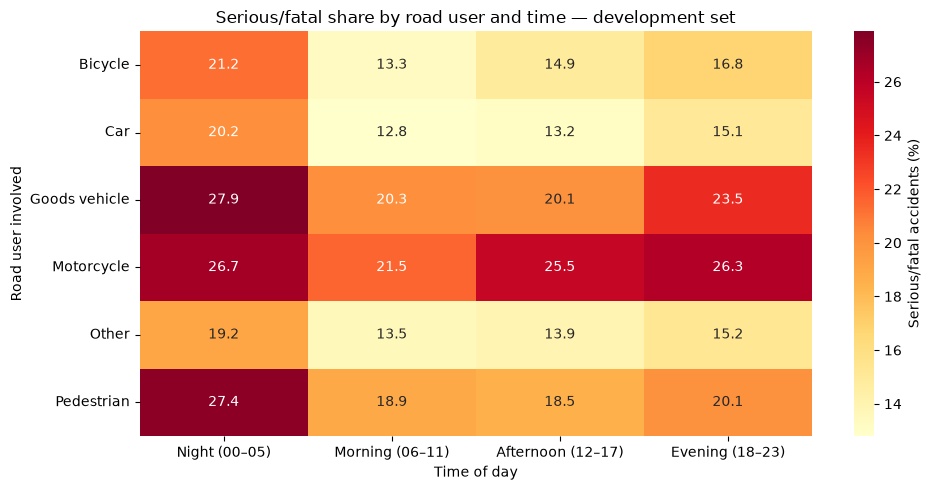

In [ ]:

# Plot severity heatmap
plt.figure(figsize=(10, 5))

sns.heatmap(
    road_time_table,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Serious/fatal accidents (%)"}
)

plt.title("Serious/fatal share by road user and time — development set")
plt.xlabel("Time of day")
plt.ylabel("Road user involved")

plt.tight_layout()
plt.show()


## 18. Accident type × circumstances

We investigate how accident type (`UART`) and accident circumstances (`UTYP1`) are related to serious/fatal outcomes.

**Goal:** Identify combinations associated with higher severity and explore whether the two features provide complementary information.

We check sample sizes to avoid drawing conclusions from rare combinations.

In [ ]:

# Group by accident type and circumstance
uart_utyp = eda.groupby(["UTYP1", "UART"]).agg(
    accidents=("serious_or_fatal", "size"),
    serious_fatal_pct=("serious_or_fatal", "mean")
)

# Convert to percentage
uart_utyp["serious_fatal_pct"] *= 100

# Show combinations with the highest severity (at least 100 accidents)
display(
    uart_utyp[uart_utyp["accidents"] >= 100]
    .sort_values("serious_fatal_pct", ascending=False)
    .head(10)
    .round(2)
)


accidents  serious_fatal_pct
UTYP1 UART                              
1     4          1568              32.33
      8         11330              27.70
6     4          6599              27.32
1     9          6754              27.08
7     8          2712              25.33
4     6          7121              24.28
7     9          1671              24.12
      4           737              23.74
6     9           416              22.84
1     7           445              21.80

### Visualization — Accident Type × Accident Circumstances

We visualize serious/fatal accident percentages for combinations of `UTYP1` and `UART`.

**Goal:** Identify accident scenarios associated with higher severity and explore whether combining these features reveals additional patterns.

We also check the number of accidents in each combination to avoid overinterpreting small groups.

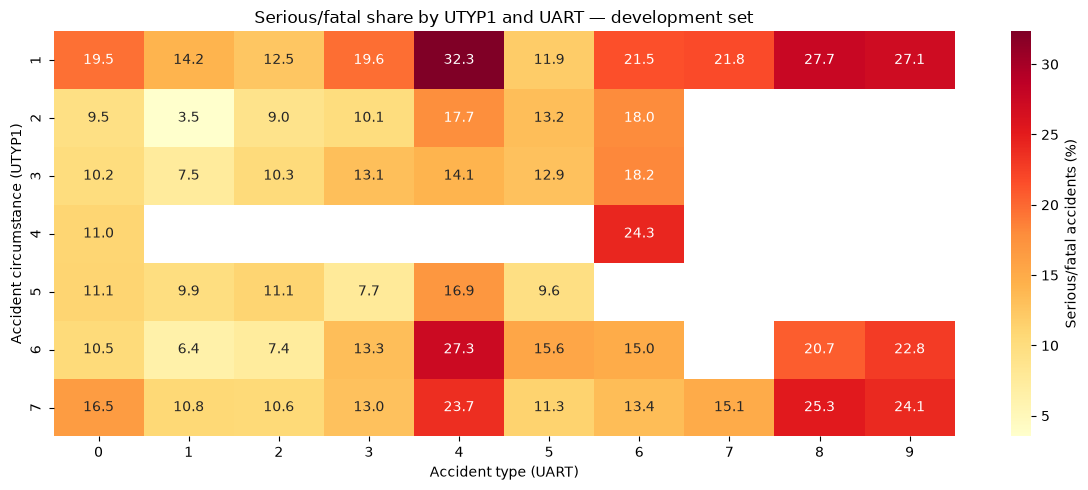

In [ ]:

# Create severity heatmap table
uart_utyp_heatmap = uart_utyp["serious_fatal_pct"].unstack("UART")

# Create accident count table
uart_utyp_counts = uart_utyp["accidents"].unstack("UART")

# Hide combinations with fewer than 100 accidents
uart_utyp_heatmap = uart_utyp_heatmap.where(
    uart_utyp_counts >= 100
)

# Plot heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    uart_utyp_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Serious/fatal accidents (%)"}
)

plt.title("Serious/fatal share by UTYP1 and UART — development set")
plt.xlabel("Accident type (UART)")
plt.ylabel("Accident circumstance (UTYP1)")

plt.tight_layout()
plt.show()


## 19. Seasonal motorcycle involvement

**Question:** Does motorcycle involvement vary by month, and could this contribute to seasonal differences in accident severity?

**Hypothesis:** Motorcycle involvement may increase during warmer months, potentially contributing to higher serious/fatal accident proportions.

We first calculate the percentage of recorded accidents involving motorcycles in each month.

In [ ]:

# Calculate motorcycle involvement by month
monthly_motorcycle = eda.groupby("UMONAT").agg(
    accidents=("IstKrad", "size"),
    motorcycle_accidents=("IstKrad", "sum"),
    motorcycle_share=("IstKrad", "mean")
)

# Convert to percentage
monthly_motorcycle["motorcycle_pct"] = (
    monthly_motorcycle["motorcycle_share"] * 100
)

# Compare motorcycle involvement with overall monthly severity
monthly_motorcycle["severity_pct"] = (
    monthly_severity["serious_fatal_pct"]
)

display(
    monthly_motorcycle[
        ["accidents", "motorcycle_accidents",
         "motorcycle_pct", "severity_pct"]
    ].round(2)
)


,accidents,motorcycle_accidents,motorcycle_pct,severity_pct
UMONAT,,,,
1,12332,607,4.92,14.33
2,10394,660,6.35,14.39
3,14197,2004,14.12,16.20
4,16567,2740,16.54,16.56
5,19414,3212,16.54,16.41
6,19462,3291,16.91,17.01
7,19329,3054,15.80,16.08
8,18500,3408,18.42,17.98
9,18127,2952,16.29,15.63


### Visualization — Motorcycle Involvement and Monthly Severity

We compare two monthly percentages:

- The percentage of recorded accidents involving motorcycles.
- The percentage of recorded accidents classified as serious/fatal.

**Goal:** Investigate whether motorcycle involvement and accident severity follow similar seasonal patterns.

Similar trends suggest a possible relationship but do not establish causation.

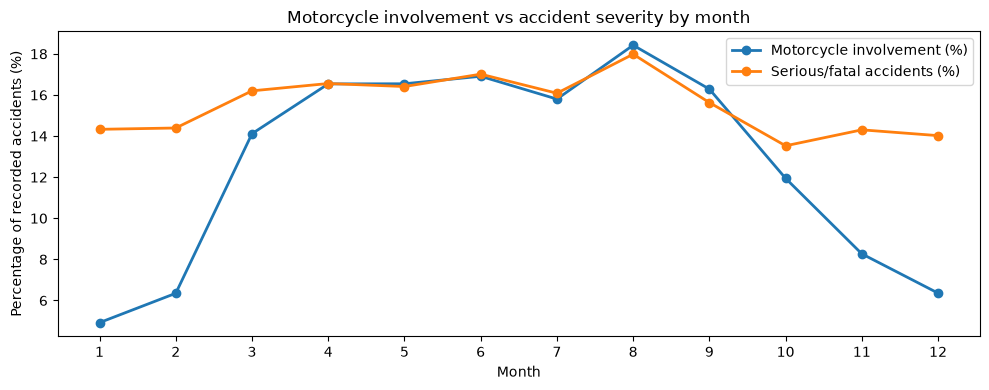

In [ ]:

# Compare monthly motorcycle involvement and severity
ax = monthly_motorcycle[
    ["motorcycle_pct", "severity_pct"]
].plot(
    figsize=(10, 4),
    marker="o",
    linewidth=2
)

ax.set_title("Motorcycle involvement vs accident severity by month")
ax.set_xlabel("Month")
ax.set_ylabel("Percentage of recorded accidents (%)")
ax.set_xticks(range(1, 13))

ax.legend([
    "Motorcycle involvement (%)",
    "Serious/fatal accidents (%)"
])

plt.tight_layout()
plt.show()


### Monthly Severity — Motorcycle vs Non-Motorcycle Accidents

We compare serious/fatal accident percentages for:

- Accidents involving motorcycles (`IstKrad = 1`).
- Accidents without motorcycle involvement (`IstKrad = 0`).

**Goal:** Investigate whether seasonal severity patterns persist within each group.

This helps distinguish changes in road-user composition from changes in severity within the groups.

In [ ]:

# Calculate monthly severity for both groups
motorcycle_severity = (
    eda.groupby(["UMONAT", "IstKrad"])["serious_or_fatal"]
    .agg(["size", "mean"])
    .reset_index()
)

# Convert severity to percentage
motorcycle_severity["severity_pct"] = (
    motorcycle_severity["mean"] * 100
)

# Create a comparison table
motorcycle_severity_table = motorcycle_severity.pivot(
    index="UMONAT",
    columns="IstKrad",
    values="severity_pct"
)

motorcycle_severity_table = motorcycle_severity_table.rename(
    columns={0: "Without motorcycle", 1: "With motorcycle"}
)

display(motorcycle_severity_table.round(2))


IstKrad,Without motorcycle,With motorcycle
UMONAT,,
1,14.18,17.13
2,13.94,21.06
3,14.46,26.80
4,14.55,26.68
5,14.34,26.87
6,14.77,28.05
7,14.62,23.87
8,15.94,27.05
9,13.92,24.39


### Visualization — Monthly Severity With and Without Motorcycles

We compare monthly serious/fatal accident percentages for accidents involving motorcycles and accidents without motorcycle involvement.

**Goal:** Determine whether seasonal severity patterns remain visible within both groups.

This helps distinguish changes in motorcycle involvement from changes in accident severity within each group.

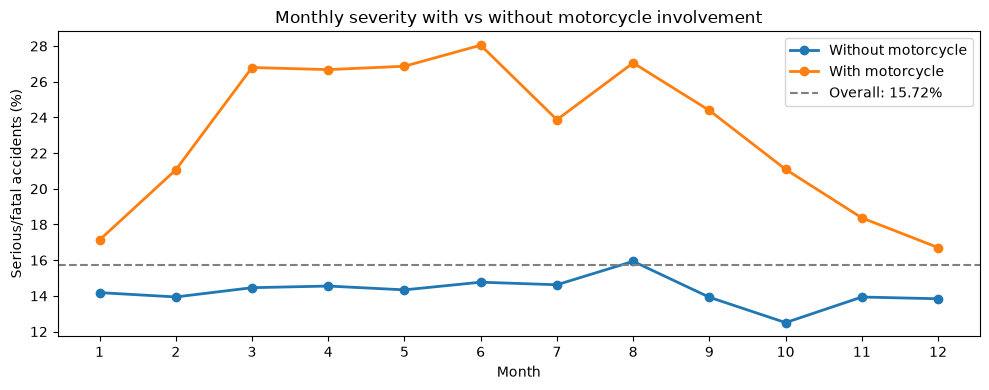

In [ ]:

# Plot monthly severity for both groups
ax = motorcycle_severity_table.plot(
    figsize=(10, 4),
    marker="o",
    linewidth=2
)

# Overall baseline
ax.axhline(
    overall_pct,
    color="grey",
    linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

ax.set_title("Monthly severity with vs without motorcycle involvement")
ax.set_xlabel("Month")
ax.set_ylabel("Serious/fatal accidents (%)")
ax.set_xticks(range(1, 13))

ax.legend()
plt.tight_layout()
plt.show()


## 20. Federal-state severity

**Question:** Do serious/fatal accident proportions differ across German federal states?

**Hypothesis:** Accident severity may vary geographically due to differences in road environments, traffic composition, and infrastructure.

We investigate federal-state differences using `ULAND` in the development dataset.

These comparisons describe recorded accidents, not the probability of an accident occurring in each state.

In [ ]:

# Check federal-state categories and accident counts
eda["ULAND"].value_counts(dropna=False).sort_index()


ULAND
01     8081
02     4932
03    17192
04     1806
05    43174
06    12933
07     8931
08    22632
09    32780
10     2210
11     9327
12     5900
13     3362
14     8905
15     5105
16     3834
Name: count, dtype: Int64

### Severity Comparison by Federal State

We calculate the percentage of serious/fatal accidents in each German federal state.

**Goal:** Identify regional differences in accident severity.

We compare both accident counts and severity percentages, since states with more recorded accidents do not necessarily have higher severity proportions.

In [ ]:

# German federal-state codes
state_labels = {
    "01": "Schleswig-Holstein",
    "02": "Hamburg",
    "03": "Lower Saxony",
    "04": "Bremen",
    "05": "North Rhine-Westphalia",
    "06": "Hesse",
    "07": "Rhineland-Palatinate",
    "08": "Baden-Württemberg",
    "09": "Bavaria",
    "10": "Saarland",
    "11": "Berlin",
    "12": "Brandenburg",
    "13": "Mecklenburg-Vorpommern",
    "14": "Saxony",
    "15": "Saxony-Anhalt",
    "16": "Thuringia"
}

# Calculate severity by federal state
state_severity = eda.groupby("ULAND").agg(
    accidents=("serious_or_fatal", "size"),
    serious_fatal_count=("serious_or_fatal", "sum"),
    serious_fatal_pct=("serious_or_fatal", "mean")
)

# Convert to percentage
state_severity["serious_fatal_pct"] *= 100

# Replace state codes with names
state_severity = state_severity.rename(index=state_labels)

# Sort from highest to lowest severity
state_severity = state_severity.sort_values(
    "serious_fatal_pct", ascending=False
)

display(state_severity.round(2))


,accidents,serious_fatal_count,serious_fatal_pct
ULAND,,,
Thuringia,3834,884,23.06
Saxony,8905,1868,20.98
Mecklenburg-Vorpommern,3362,684,20.35
Saxony-Anhalt,5105,1016,19.90
Rhineland-Palatinate,8931,1512,16.93
Brandenburg,5900,988,16.75
Bavaria,32780,5464,16.67
Saarland,2210,347,15.70
Baden-Württemberg,22632,3499,15.46


### Visualization — Accident Severity by Federal State

We compare serious/fatal accident proportions across Germany's 16 federal states.

**Goal:** Identify regional differences and investigate whether geographic information could be useful for severity prediction.

The dashed line represents the overall average (15.72%).

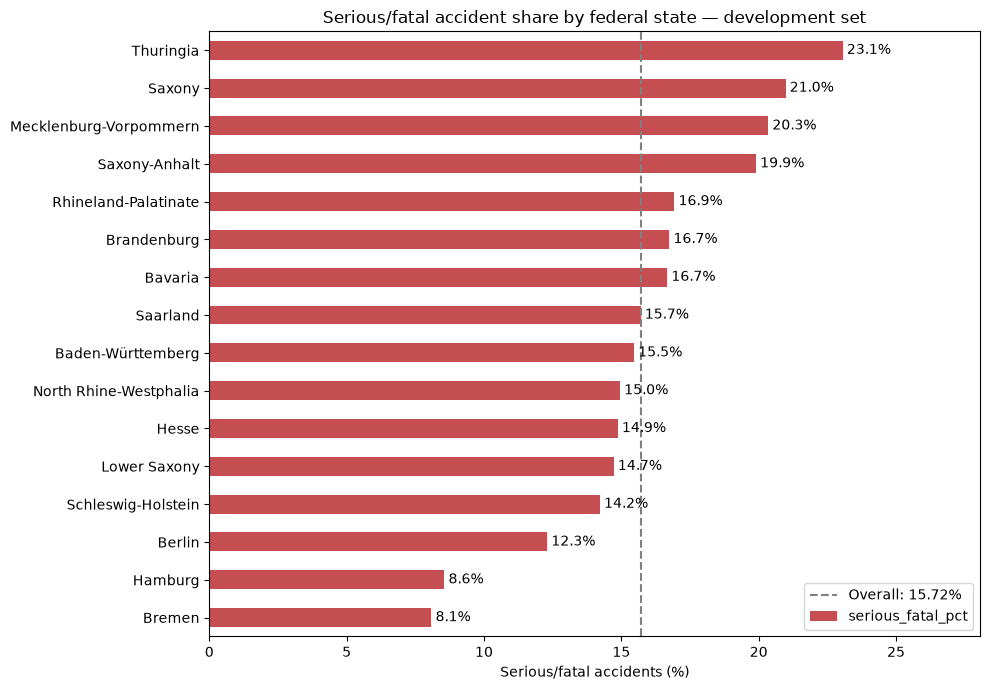

In [ ]:

# Plot serious/fatal accident share by federal state
ax = state_severity["serious_fatal_pct"].sort_values().plot.barh(
    figsize=(10, 7),
    color="#c44e52"
)

# Add overall average
ax.axvline(
    overall_pct,
    color="grey",
    linestyle="--",
    label=f"Overall: {overall_pct:.2f}%"
)

ax.set_title("Serious/fatal accident share by federal state — development set")
ax.set_xlabel("Serious/fatal accidents (%)")
ax.set_ylabel("")
ax.set_xlim(0, state_severity["serious_fatal_pct"].max() + 5)

# Add percentage labels
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

ax.legend()
plt.tight_layout()
plt.show()


## 21. State × road-user involvement

**Question:** Does road-user involvement vary between German federal states?

**Hypothesis:** Differences in road-user involvement may partly explain regional differences in serious/fatal accident proportions.

We compare the percentage of accidents involving motorcycles, bicycles, pedestrians, and cars across states.

These groups can overlap because an accident may involve multiple road-user types.

In [ ]:

# Select road-user columns for comparison
users_to_compare = {
    "IstKrad": "Motorcycle",
    "IstRad": "Bicycle",
    "IstFuss": "Pedestrian",
    "IstPKW": "Car"
}

# Calculate percentage of accidents involving each road-user type
state_road_users = (
    eda.groupby("ULAND")[list(users_to_compare)]
    .mean() * 100
)

# Replace state and road-user codes with names
state_road_users = state_road_users.rename(
    index=state_labels,
    columns=users_to_compare
)

# Order by overall serious/fatal share
state_road_users = state_road_users.reindex(state_severity.index)

display(state_road_users.round(2))


,Motorcycle,Bicycle,Pedestrian,Car
ULAND,,,,
Thuringia,18.70,24.18,8.48,74.33
Saxony,14.60,35.55,9.52,72.18
Mecklenburg-Vorpommern,11.72,32.30,8.09,74.42
Saxony-Anhalt,13.03,30.75,7.05,74.34
Rhineland-Palatinate,18.17,21.80,7.49,75.42
Brandenburg,13.29,33.64,7.24,73.71
Bavaria,14.26,36.49,7.14,66.96
Saarland,15.70,17.47,8.28,76.83
Baden-Württemberg,14.97,33.80,8.03,69.09


### Visualization — Road-User Involvement by Federal State

We compare the percentage of recorded accidents involving different road-user types across German federal states.

**Goal:** Explore whether states with higher accident severity also have different road-user involvement patterns.

These percentages measure involvement, not severity, and categories may overlap.

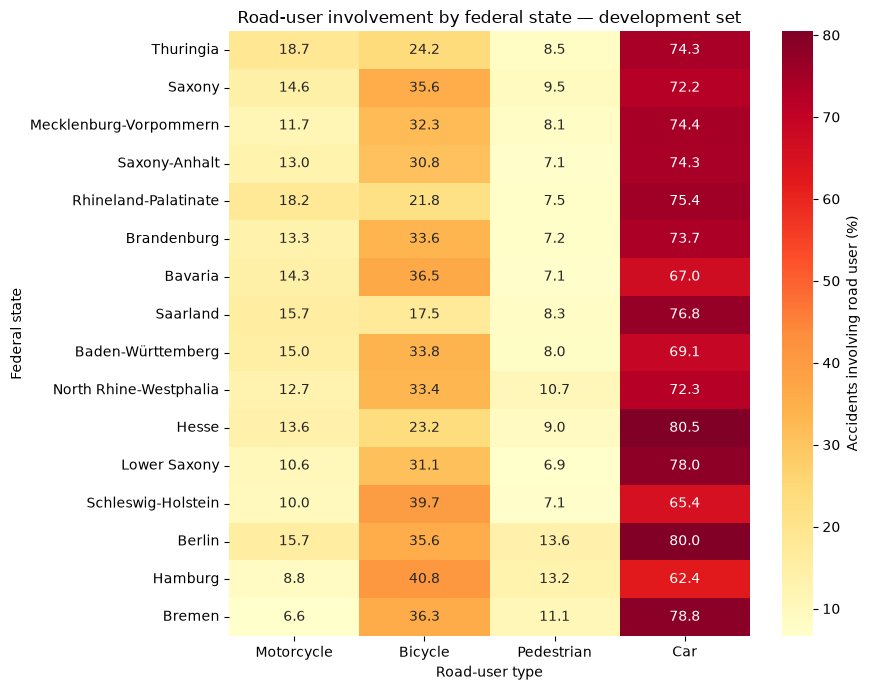

In [ ]:

# Plot road-user involvement by federal state
plt.figure(figsize=(9, 7))

sns.heatmap(
    state_road_users,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Accidents involving road user (%)"}
)

plt.title("Road-user involvement by federal state — development set")
plt.xlabel("Road-user type")
plt.ylabel("Federal state")

plt.tight_layout()
plt.show()


### Severity by Federal State and Road-User Involvement

**Question:** Are accidents involving the same road-user category more severe in some states than others?

We calculate the serious/fatal accident percentage within each road-user category for every state.

**Goal:** Investigate whether regional severity differences remain when comparing similar road-user involvement groups.

These comparisons remain observational and do not control for road type, speed, or accident circumstances.

In [ ]:

# Calculate severity within each road-user group for every state
state_user_results = []

for col, label in users_to_compare.items():
    involved = eda[eda[col] == 1]

    for state, group in involved.groupby("ULAND"):
        state_user_results.append({
            "state": state_labels[state],
            "road_user": label,
            "accidents": len(group),
            "serious_fatal_pct": group["serious_or_fatal"].mean() * 100
        })

# Convert to DataFrame
state_user_severity = pd.DataFrame(state_user_results)

# Create comparison table
state_user_table = state_user_severity.pivot(
    index="state",
    columns="road_user",
    values="serious_fatal_pct"
).reindex(state_severity.index)

display(state_user_table.round(2))


road_user,Bicycle,Car,Motorcycle,Pedestrian
ULAND,,,,
Thuringia,20.60,20.74,31.94,29.23
Saxony,17.88,18.62,30.62,28.18
Mecklenburg-Vorpommern,17.31,17.11,30.71,31.62
Saxony-Anhalt,16.18,18.37,29.92,20.28
Rhineland-Palatinate,17.82,14.34,28.10,21.67
Brandenburg,15.21,14.90,25.51,18.50
Bavaria,17.12,14.09,25.92,19.20
Saarland,21.24,13.55,24.21,19.13
Baden-Württemberg,15.56,13.35,24.11,18.33


### Sample Size Check — State × Road User

We check the number of accidents in each state and road-user combination.

**Goal:** Make sure observed differences in severity are not based on very small groups.

In [ ]:

# Create accident count table
state_user_counts = state_user_severity.pivot(
    index="state",
    columns="road_user",
    values="accidents"
).reindex(state_severity.index)

display(state_user_counts)

print("Smallest group:", state_user_counts.min().min())


road_user,Bicycle,Car,Motorcycle,Pedestrian
ULAND,,,,
Thuringia,927,2850,717,325
Saxony,3166,6428,1300,848
Mecklenburg-Vorpommern,1086,2502,394,272
Saxony-Anhalt,1570,3795,665,360
Rhineland-Palatinate,1947,6736,1623,669
Brandenburg,1985,4349,784,427
Bavaria,11960,21948,4676,2339
Saarland,386,1698,347,183
Baden-Württemberg,7650,15637,3389,1817


Smallest group: 120


### Visualization — State × Road-User Severity

We compare the serious/fatal accident percentage within each road-user category across federal states.

This helps us examine whether geographic differences remain when comparing accidents involving similar types of road users.

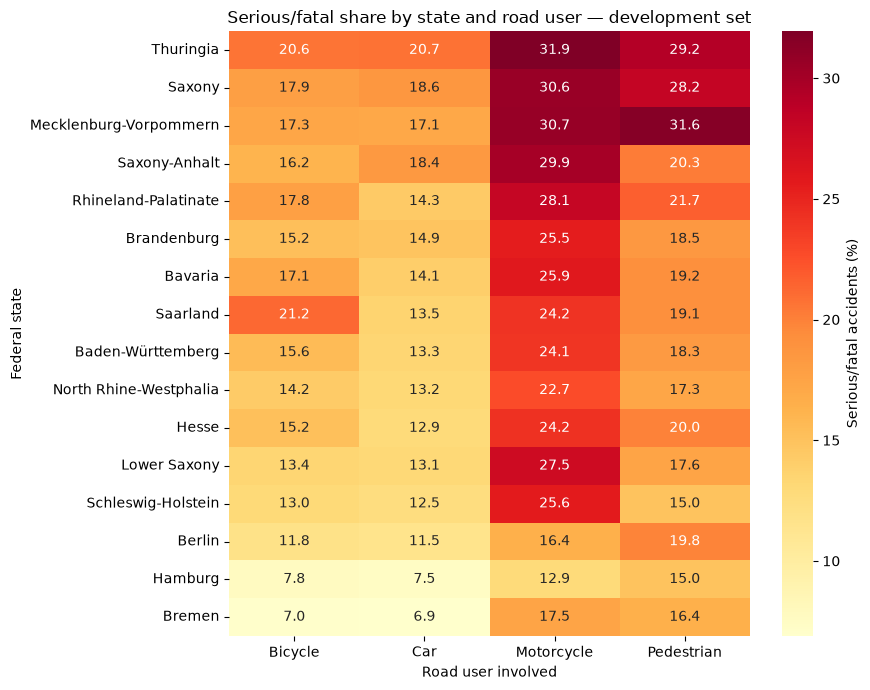

In [ ]:

# Visualize serious/fatal share by state and road user
plt.figure(figsize=(9, 7))

sns.heatmap(
    state_user_table,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Serious/fatal accidents (%)"}
)

plt.title("Serious/fatal share by state and road user — development set")
plt.xlabel("Road user involved")
plt.ylabel("Federal state")

plt.tight_layout()
plt.show()


## 22. State × accident circumstances

We investigate whether the distribution of accident circumstances (`UTYP1`) varies between German federal states.

**Hypothesis:** Differences in accident circumstances may partly explain regional differences in serious/fatal accident proportions.

We compare the percentage of recorded accidents belonging to each `UTYP1` category within each state.

In [ ]:

# Count accidents by state and accident circumstance
state_utyp_counts = pd.crosstab(
    eda["ULAND"],
    eda["UTYP1"]
)

# Convert counts to percentages within each state
state_utyp_pct = (
    state_utyp_counts.div(state_utyp_counts.sum(axis=1), axis=0)
    * 100
)

# Replace state codes with names
state_utyp_pct = state_utyp_pct.rename(index=state_labels)

# Order states by overall severity
state_utyp_pct = state_utyp_pct.reindex(state_severity.index)

display(state_utyp_pct.round(2))


UTYP1,1,2,3,4,5,6,7
ULAND,,,,,,,
Thuringia,24.49,11.11,21.07,4.09,2.35,23.68,13.20
Saxony,23.23,14.14,21.98,4.75,3.45,18.27,14.18
Mecklenburg-Vorpommern,23.88,12.22,21.27,4.10,2.17,25.16,11.18
Saxony-Anhalt,22.00,13.77,22.96,4.19,3.25,22.82,11.01
Rhineland-Palatinate,26.41,11.97,19.23,3.66,3.65,24.45,10.63
Brandenburg,19.44,13.92,25.27,3.36,3.27,22.19,12.56
Bavaria,24.62,10.05,20.40,2.93,1.60,23.14,17.26
Saarland,16.11,10.95,15.52,4.16,5.48,25.48,22.31
Baden-Württemberg,19.81,9.90,21.53,3.73,2.64,26.74,15.65


### Visualization — Accident Circumstances by Federal State

We visualize the percentage of recorded accidents belonging to each `UTYP1` category across federal states.

**Goal:** Explore whether differences in accident circumstances may contribute to geographic differences in accident severity.

These percentages represent accident-category frequency, not injury severity.

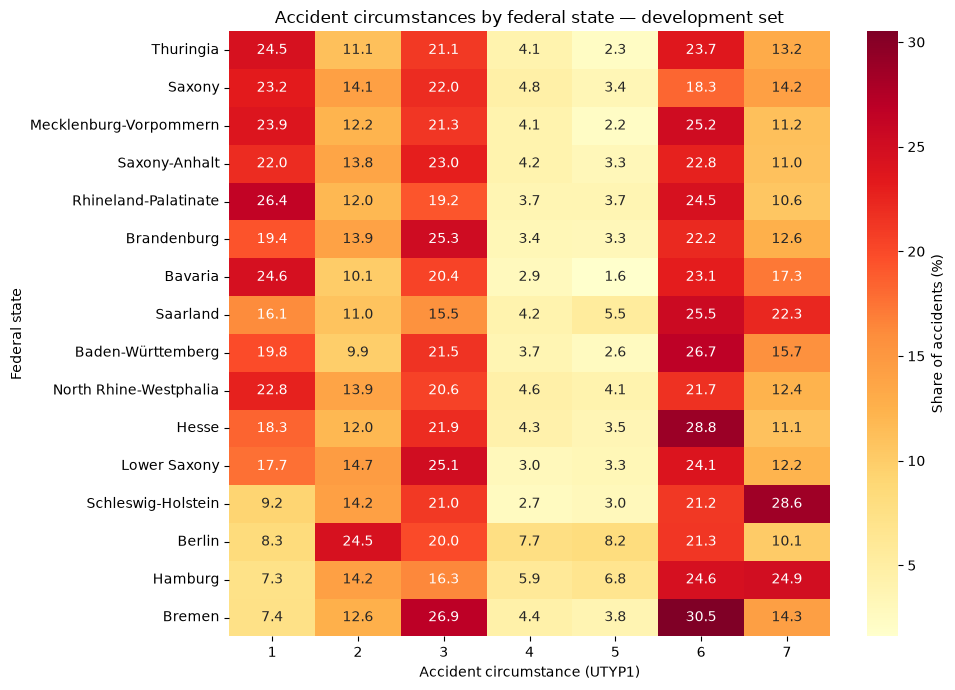

In [ ]:

# Visualize UTYP1 distribution across states
plt.figure(figsize=(10, 7))

sns.heatmap(
    state_utyp_pct,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Share of accidents (%)"}
)

plt.title("Accident circumstances by federal state — development set")
plt.xlabel("Accident circumstance (UTYP1)")
plt.ylabel("Federal state")

plt.tight_layout()
plt.show()


### EDA Insight — Geographic Accident Circumstances

- The distribution of accident circumstances varies considerably between federal states.
- UTYP1 = 1 accounts for approximately 23–25% of accidents in Thuringia, Saxony, and Bavaria, compared with 7–8% in Berlin, Hamburg, and Bremen.
- UTYP1 = 4 does not follow this pattern.
- Differences in accident circumstances may contribute to regional severity differences, but further analysis is needed.
- These results describe category composition rather than severity within each category.

## 23. State × circumstance severity

**Question:** Do regional severity differences remain within the same accident circumstance categories?

We compare serious/fatal accident percentages for each `UTYP1` category across federal states.

**Goal:** Investigate whether geographic severity differences persist when comparing accidents with similar circumstances.

These comparisons do not control for every possible factor.

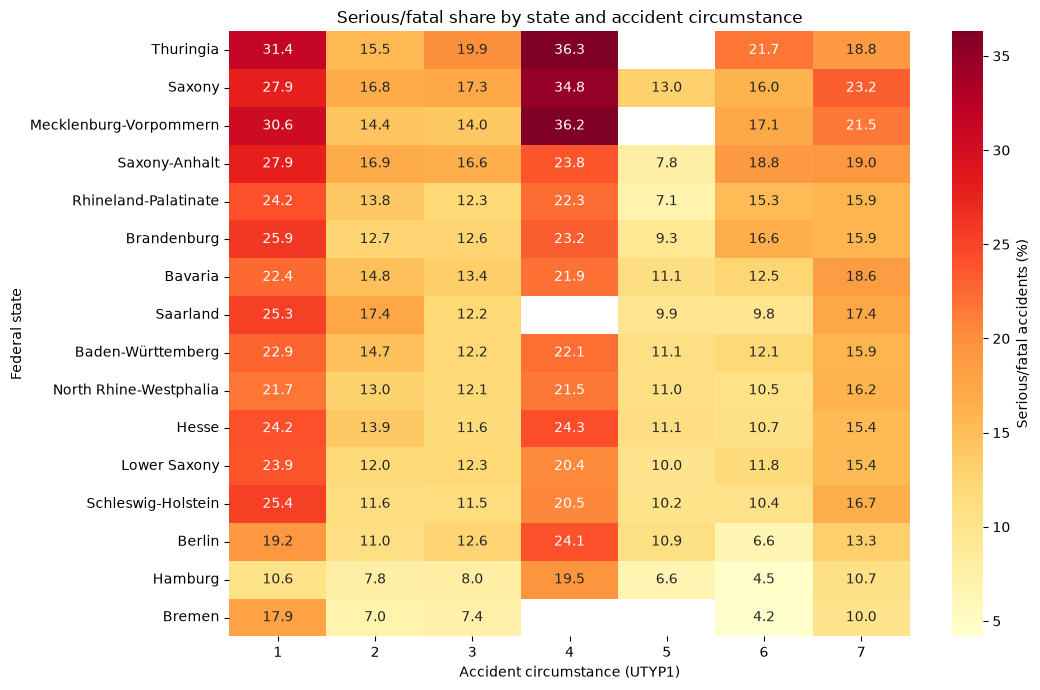

Smallest group: 69


In [ ]:

# Calculate severity within each state and accident circumstance
state_utyp_severity = eda.pivot_table(
    index="ULAND",
    columns="UTYP1",
    values="serious_or_fatal",
    aggfunc="mean"
) * 100

# Count accidents in each combination
state_utyp_counts = pd.crosstab(
    eda["ULAND"],
    eda["UTYP1"]
)

# Apply state labels and order
state_utyp_severity = state_utyp_severity.rename(index=state_labels)
state_utyp_counts = state_utyp_counts.rename(index=state_labels)

state_utyp_severity = state_utyp_severity.reindex(state_severity.index)
state_utyp_counts = state_utyp_counts.reindex(state_severity.index)

# Mask groups with fewer than 100 accidents
state_utyp_severity = state_utyp_severity.where(
    state_utyp_counts >= 100
)

# Plot heatmap
plt.figure(figsize=(11, 7))

sns.heatmap(
    state_utyp_severity,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Serious/fatal accidents (%)"}
)

plt.title("Serious/fatal share by state and accident circumstance")
plt.xlabel("Accident circumstance (UTYP1)")
plt.ylabel("Federal state")

plt.tight_layout()
plt.show()

print("Smallest group:", state_utyp_counts.min().min())


## 24. Spatial coordinates and geographic patterns

**Question:** Can accident coordinates help us identify geographic patterns in accident severity?

We check whether the dataset contains valid longitude and latitude values.

**Goal:** Determine whether the coordinates can support mapping, hotspot analysis, and comparisons between different geographic environments.

In [ ]:

# Select coordinate columns
coords = ["XGCSWGS84", "YGCSWGS84"]

# Check missing values and coordinate ranges
display(eda[coords].describe())

print("Missing coordinates:")
print(eda[coords].isna().sum())

# Check whether coordinates fall within Germany's approximate bounds
valid_coords = (
    eda["XGCSWGS84"].between(5.5, 15.5)
    & eda["YGCSWGS84"].between(47.0, 55.5)
)

print("Coordinates within approximate German bounds:",
      valid_coords.sum())

print("Coordinates outside bounds:",
      (~valid_coords).sum())

# Check repeated coordinate pairs
print("Repeated coordinate pairs:",
      eda.duplicated(subset=coords).sum())


,XGCSWGS84,YGCSWGS84
count,191104.000000,191104.000000
mean,9.699109,50.857447
std,2.171356,1.768511
min,5.884659,47.308169
25%,7.882347,49.386115
50%,9.445998,51.034635
75%,11.435507,52.244700
max,15.027292,55.048351


Missing coordinates:
XGCSWGS84    0
YGCSWGS84    0
dtype: int64
Coordinates within approximate German bounds: 191104
Coordinates outside bounds: 0
Repeated coordinate pairs: 1812


### 24.1 Spatial accident frequency

We visualize where recorded accidents are concentrated geographically.

**Goal:** Identify spatial patterns and areas with higher numbers of recorded accidents.

We use a hexbin plot to aggregate nearby accident locations instead of displaying every accident separately.

**Important:** Higher accident counts do not necessarily indicate higher accident risk because traffic exposure differs between locations.

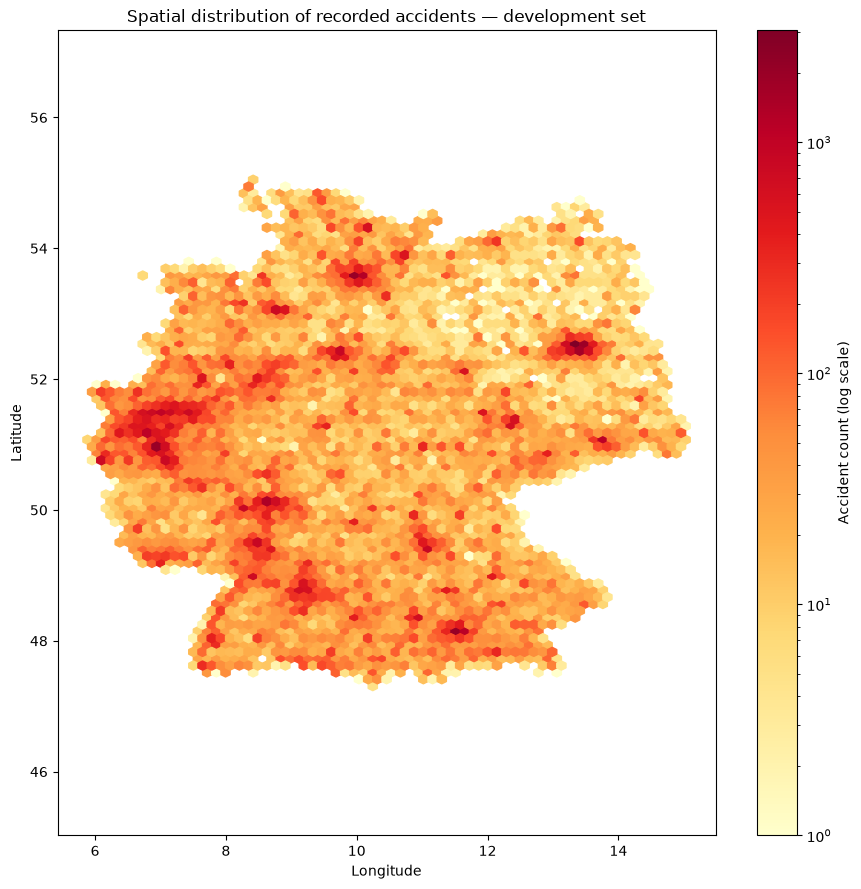

In [ ]:

# Plot spatial distribution of recorded accidents
plt.figure(figsize=(9, 9))

hb = plt.hexbin(
    eda["XGCSWGS84"],
    eda["YGCSWGS84"],
    gridsize=65,
    cmap="YlOrRd",
    mincnt=1,
    bins="log"
)

plt.colorbar(hb, label="Accident count (log scale)")

plt.title("Spatial distribution of recorded accidents — development set")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.axis("equal")

plt.tight_layout()
plt.show()


### 24.2 Spatial severity proportions

We investigate how serious/fatal accident proportions vary geographically across Germany.

**Goal:** Identify areas where recorded accidents have higher severity proportions.

We aggregate accidents into geographic hexagons and exclude cells containing fewer than 30 accidents to reduce the influence of very small samples.

**Note:** Higher severity proportions do not necessarily indicate a higher probability of an accident occurring.

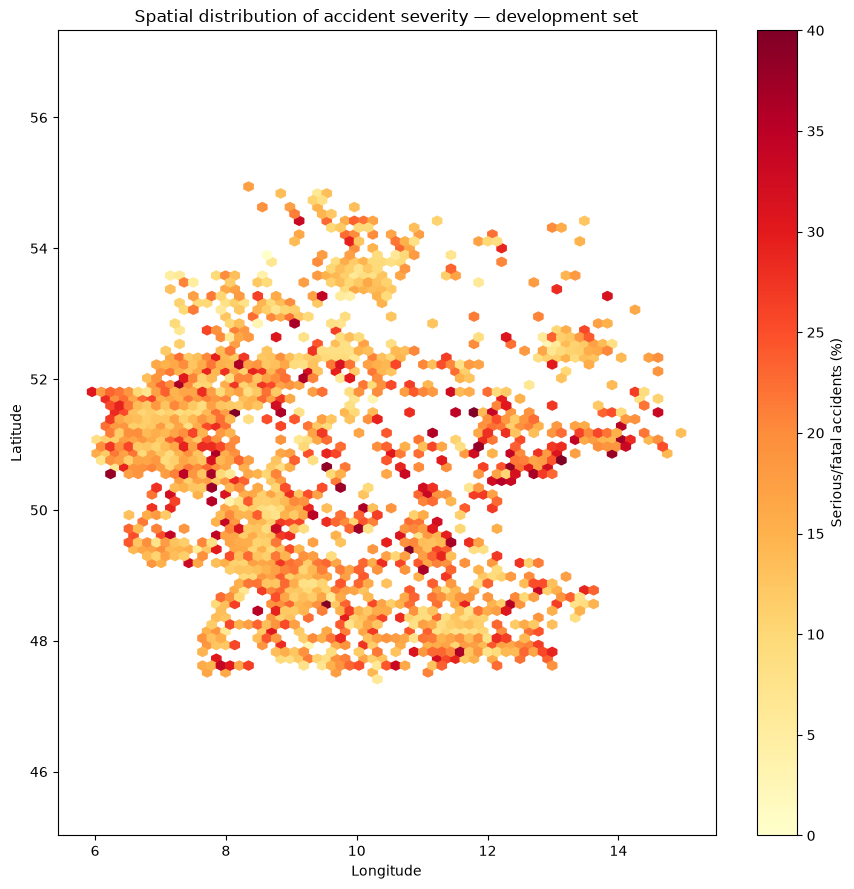

In [ ]:
import numpy as np
# Plot serious/fatal percentage within geographic hexagons
plt.figure(figsize=(9, 9))

hb = plt.hexbin(
    eda["XGCSWGS84"],
    eda["YGCSWGS84"],
    C=eda["serious_or_fatal"].astype(int) * 100,
    reduce_C_function=np.mean,
    gridsize=65,
    mincnt=30,
    cmap="YlOrRd",
    vmin=0,
    vmax=40
)

plt.colorbar(hb, label="Serious/fatal accidents (%)")

plt.title("Spatial distribution of accident severity — development set")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.axis("equal")

plt.tight_layout()
plt.show()


### EDA Insight — Spatial Accident Patterns

- Recorded accidents are geographically concentrated, particularly around major urban regions.
- Accident frequency and serious/fatal severity proportions show different spatial patterns.
- Some areas with fewer recorded accidents show higher severity proportions.
- Geographic coordinates may provide useful information for investigating regional accident severity.
- Hexagons with fewer than 30 accidents were excluded from the severity map.
- These visualizations describe recorded accidents and do not establish accident risk or identify causal geographic factors.

## 28. Live summary from this run (training data only)

The compact table below is recalculated from the current 70% training subset. Prefer these figures over historical Markdown percentages left in earlier insight notes.


In [ ]:
# Recalculate key findings from the currently selected training rows.
current_findings = pd.DataFrame([
    {"Analysis": "Overall", "Group": "All training accidents", "Accidents": len(eda), "Serious/fatal %": overall_pct},
    {"Analysis": "Time", "Group": "03:00", "Accidents": int((eda["USTUNDE"]==3).sum()),
     "Serious/fatal %": 100 * eda.loc[eda["USTUNDE"]==3, "serious_or_fatal"].mean()},
    {"Analysis": "Weekday", "Group": "Sunday", "Accidents": int((eda["UWOCHENTAG"]==1).sum()),
     "Serious/fatal %": 100 * eda.loc[eda["UWOCHENTAG"]==1, "serious_or_fatal"].mean()},
    {"Analysis": "Road users (descriptive)", "Group": "Motorcycle involved", "Accidents": int(eda["IstKrad"].sum()),
     "Serious/fatal %": 100 * eda.loc[eda["IstKrad"]==1, "serious_or_fatal"].mean()},
    {"Analysis": "Region", "Group": "Thuringia", "Accidents": int((eda["ULAND"]=="16").sum()),
     "Serious/fatal %": 100 * eda.loc[eda["ULAND"]=="16", "serious_or_fatal"].mean()},
    {"Analysis": "Region", "Group": "Hamburg", "Accidents": int((eda["ULAND"]=="02").sum()),
     "Serious/fatal %": 100 * eda.loc[eda["ULAND"]=="02", "serious_or_fatal"].mean()},
])
display(current_findings.round(2))


,Analysis,Group,Accidents,Serious/fatal %
0,Overall,All training accidents,191104,15.72
1,Time,03:00,897,26.31
2,Weekday,Sunday,17811,19.82
3,Road users (descriptive),Motorcycle involved,25793,24.87
4,Region,Thuringia,3834,23.06
5,Region,Hamburg,4932,8.56


### Discussion and next steps

1. Compare the severity associations above with **frequency** (where/when many accidents are recorded). Neither is traffic exposure or accident incidence risk.
2. Treat `UART` and `UTYP1` as descriptive, post-accident-only fields. Participant involvement can additionally support **explicit hypothetical scenarios**, but not automatic predictions of who will be involved.
3. Agree on shared 70/15/15 **row identifiers** before model comparisons; notebook-local stratification is not sufficient proof of shared split membership.
4. Compare the scenario-based rule baseline below with a time-and-location-only baseline, then explore fitted models using only inputs available or explicitly assumed at prediction time.
5. Use ROC-AUC, PR-AUC, precision, recall, and calibration in addition to accuracy. Keep final test results unseen until selection is complete.

**Unresolved:** Whether reconstructed exact dates from accident IDs can be validated sufficiently for calendar features, and whether geographic holdouts change performance.


## 29. Modeling — Michael’s Baseline 3 (hypothetical scenario)

**Question:** If an injury accident has the specified road-user involvement, does a simple rule correctly flag serious/fatal outcomes?

This **rule-based baseline** predicts serious/fatal injury when **a motorcycle is involved OR a pedestrian is involved OR no passenger car is involved**. It does *not* learn parameters from training data.

- Evaluate on the **validation** portion only. Reserve the test set for final evaluation.
- Participant indicators are **assumed characteristics of a hypothetical collision**, not known facts about an accident that hasn't occurred.
- We are predicting **severity conditional on an injury accident**, not the probability that an accident occurs.
- The current notebook's local split is not guaranteed to match the shared team split files. Align row memberships before reporting group-comparable metrics.


In [ ]:
# Binary target: 0 = slight injury; 1 = serious or fatal injury.
y_train = train["UKATEGORIE"].isin([1, 2]).astype(int)
y_val = validation["UKATEGORIE"].isin([1, 2]).astype(int)

print(f"Training accidents:   {len(y_train):,}")
print(f"Validation accidents: {len(y_val):,}")
print("\nValidation class proportions:")
print(y_val.value_counts(normalize=True).sort_index().round(3))

Training accidents:   191,104
Validation accidents: 40,951

Validation class proportions:
UKATEGORIE
0    0.843
1    0.157
Name: proportion, dtype: float64


### 29.1 Apply the three-condition rule

The three `Ist...` fields are indicators of **reported categories involved**, not the number of people or vehicles. Here we evaluate the original rule against observed historical cases; using it prospectively requires explicitly setting the participant scenario.

In [ ]:
# Michael's Baseline 3: a fixed rule, not a trained classifier.
def michael_baseline_3(data):
    return (
        (data["IstKrad"] == 1)   # Motorcycle involved
        | (data["IstFuss"] == 1) # Pedestrian involved
        | (data["IstPKW"] == 0)  # No passenger car involved
    ).astype(int)

y_pred_baseline3 = michael_baseline_3(validation)
print("Predicted validation labels:")
print(y_pred_baseline3.value_counts().sort_index())

Predicted validation labels:
0    24411
1    16540
Name: count, dtype: int64


### 29.2 Evaluate on validation data

**Precision:** Of accidents flagged serious/fatal, how many actually were? **Recall:** How many serious/fatal accidents did the rule detect? **F1:** Balance between precision and recall. **F2:** Emphasizes recall more. The confusion matrix shows correct and incorrect predictions. Do not compare these values directly with Michael's older 80/20 test-set results.

               precision    recall  f1-score   support

       Slight       0.88      0.62      0.73     34515
Serious/Fatal       0.21      0.54      0.30      6436

     accuracy                           0.61     40951
    macro avg       0.55      0.58      0.52     40951
 weighted avg       0.77      0.61      0.66     40951

F1 score: 0.304
F2 score: 0.412


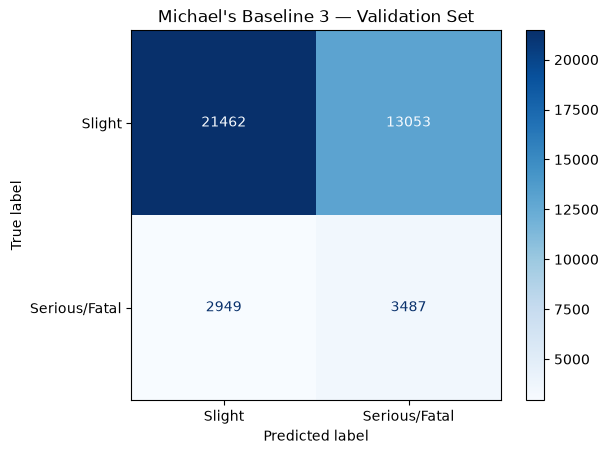

In [ ]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
)
import matplotlib.pyplot as plt

print(classification_report(
    y_val, y_pred_baseline3,
    labels=[0, 1],
    target_names=["Slight", "Serious/Fatal"],
    zero_division=0,
))
print("F1 score:", round(f1_score(y_val, y_pred_baseline3), 3))
print("F2 score:", round(fbeta_score(y_val, y_pred_baseline3, beta=2), 3))

ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_baseline3,
    labels=[0, 1],
    display_labels=["Slight", "Serious/Fatal"],
    cmap="Blues",
)
plt.title("Michael's Baseline 3 — Validation Set")
plt.show()

### Next: Our own scenario-rate baseline

Section 30 uses training-only historical severity frequencies to estimate scenario probabilities. The existing rule above stays available for comparison.

## 30. Baseline — Historical Scenario Severity Rate

**Business question:** *If an injury accident occurred at a specified place and time, involving specified road users, what is the estimated chance of serious/fatal injury?*

Instead of a fixed rule, we learn **historical severity proportions** from the **training data only**. This first version groups accidents by **federal state, night/day, weekend/weekday and the complete reported road-user combination**.

- `0` = slight injury; `1` = serious/fatal injury.
- Road-user indicators are supplied as **what-if conditions** in a prospective scenario; historical records supply those values during training/evaluation.
- We deliberately leave out `UART` and `UTYP1` (post-event accident details).
- The model does **not** predict if or where accidents will happen. It also does not prove causal effects of changing road use.
- All results below use **validation data**; the test set remains untouched.

**Split note:** This notebook makes its own reproducible 70/15/15 split. Before team-wide score comparisons, align its rows with the shared `data/splits/` files.

### 30.1 Prepare the scenario fields

We turn exact hour and weekday into broad groups for a simple first baseline. We combine the six participant indicators into a **scenario key** so that a motorcycle+car accident differs from a pedestrian+car accident. The key counts **categories of involved road users**, not the number of people or vehicles.

In [ ]:
PARTICIPANTS = [
    "IstRad", "IstPKW", "IstFuss",
    "IstKrad", "IstGkfz", "IstSonstige"
]

def prepare_scenarios(data):
    result = data.copy()
    result[PARTICIPANTS] = result[PARTICIPANTS].astype(int)

    # Night is an illustrative time definition: 22:00–05:59.
    result["is_night"] = result["USTUNDE"].isin(
        [22, 23, 0, 1, 2, 3, 4, 5]
    ).astype(int)

    # Official Unfallatlas weekday codes: Sunday=1, Saturday=7.
    result["is_weekend"] = result["UWOCHENTAG"].isin([1, 7]).astype(int)

    # Keep simultaneous participant categories together.
    result["participant_profile"] = (
        result[PARTICIPANTS].astype(str).agg("".join, axis=1)
    )
    result["target"] = result["UKATEGORIE"].isin([1, 2]).astype(int)
    return result

train_scenarios = prepare_scenarios(train)
val_scenarios = prepare_scenarios(validation)

print("Training records:", len(train_scenarios))
print("Validation records:", len(val_scenarios))
print("Training severe-injury proportion:", round(train_scenarios["target"].mean(), 3))

Training records: 191104
Validation records: 40951
Training severe-injury proportion: 0.157


### 30.2 Fit the historical-rate model

For each scenario group, count serious/fatal accidents. To avoid extreme estimates for small groups, **smooth** the group's rate toward the overall training rate:

\[
\widehat{p}_{group}=\frac{n_{severe}+\alpha\,p_{train}}{n_{group}+\alpha}
\]

Here `alpha = 100` is a **starting assumption**, not a tuned value. Unseen combinations fall back to the overall training proportion.

In [ ]:
GROUP_COLS = ["ULAND", "is_night", "is_weekend", "participant_profile"]
SMOOTHING = 100  # Strength of smoothing toward the global rate

global_rate = train_scenarios["target"].mean()
scenario_stats = (
    train_scenarios.groupby(GROUP_COLS, dropna=False)["target"]
    .agg(severe_count="sum", total_count="count")
    .reset_index()
)
scenario_stats["probability"] = (
    scenario_stats["severe_count"] + SMOOTHING * global_rate
) / (scenario_stats["total_count"] + SMOOTHING)

print("Overall training severity rate:", f"{global_rate:.1%}")
print("Distinct scenario groups:", len(scenario_stats))
print("Groups with fewer than 20 training records:",
      (scenario_stats["total_count"] < 20).sum())
display(scenario_stats.sort_values("total_count", ascending=False).head(10))

Overall training severity rate: 15.7%
Distinct scenario groups: 1327
Groups with fewer than 20 training records: 767


,ULAND,is_night,is_weekend,participant_profile,severe_count,total_count,probability
332,05,0,0,010000,978,9080,0.108248
711,09,0,0,010000,874,7738,0.113513
353,05,0,0,110000,546,5937,0.093046
618,08,0,0,010000,491,5101,0.097427
172,03,0,0,010000,532,4764,0.112606
722,09,0,0,100000,810,3990,0.201887
442,06,0,0,010000,382,3675,0.105355
345,05,0,0,100000,688,3533,0.193701
730,09,0,0,110000,382,3528,0.109624
333,05,0,0,010001,250,2712,0.094494


### 30.3 Predict validation probabilities

Each validation accident is matched to its training-data scenario group. We never use its severity label to calculate its predicted probability. For a combination never seen in training, we use the overall training rate.

We compare against a **constant-probability baseline** (equivalent to a prior-only `DummyClassifier`): every accident gets the overall training severe-injury rate.

In [ ]:
# Merge without changing the row order of validation observations.
val_predictions = val_scenarios[GROUP_COLS + ["target"]].reset_index(drop=True).merge(
    scenario_stats[GROUP_COLS + ["probability", "total_count"]],
    on=GROUP_COLS, how="left", sort=False, validate="many_to_one"
)

assert len(val_predictions) == len(val_scenarios)
y_true_scenario = val_predictions["target"]
y_prob_scenario = val_predictions["probability"].fillna(global_rate)
y_prob_constant = pd.Series(global_rate, index=val_predictions.index)

print("Unseen validation scenarios:", val_predictions["probability"].isna().sum())
print("First predicted probabilities:")
display(pd.DataFrame({
    "actual_severe": y_true_scenario,
    "scenario_probability": y_prob_scenario,
    "constant_probability": y_prob_constant
}).head())

Unseen validation scenarios: 44
First predicted probabilities:


,actual_severe,scenario_probability,constant_probability
0,0,0.207734,0.157166
1,0,0.169150,0.157166
2,0,0.108248,0.157166
3,0,0.113513,0.157166
4,0,0.118014,0.157166


### 30.4 Evaluate probabilities and classification

- **Average precision (PR-AUC summary):** How well the probabilities rank severe cases.
- **Brier score:** Average squared probability error (lower is better).
- **Precision / recall / F1 / F2:** Performance after converting probabilities to class predictions.

We use a **provisional 20% cutoff** for the scenario model. This is not optimized; a later validation exercise can compare thresholds. The constant baseline is evaluated at the same cutoff for context.

,model,average_precision,roc_auc,brier_score,precision,recall,f1,f2
0,Constant probability,0.157,0.500,0.132,0.157,1.000,0.272,0.482
1,Our scenario-rate baseline,0.230,0.625,0.129,0.211,0.617,0.315,0.446


Scenario model classification report (threshold=0.15):
               precision    recall  f1-score   support

       Slight       0.89      0.57      0.70     34515
Serious/Fatal       0.21      0.62      0.31      6436

     accuracy                           0.58     40951
    macro avg       0.55      0.59      0.51     40951
 weighted avg       0.78      0.58      0.64     40951



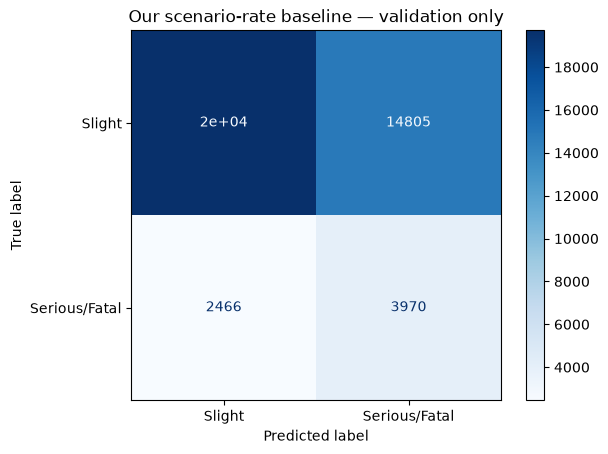

In [ ]:
from sklearn.metrics import (
    average_precision_score, brier_score_loss, roc_auc_score,
    precision_score, recall_score, f1_score, fbeta_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

THRESHOLD = 0.15  # Provisional comparison cutoff; not a final decision

def evaluate_scenario_probabilities(name, y_true, probabilities, threshold=THRESHOLD):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "model": name,
        "average_precision": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "brier_score": brier_score_loss(y_true, probabilities),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "f2": fbeta_score(y_true, predictions, beta=2, zero_division=0),
    }

results = pd.DataFrame([
    evaluate_scenario_probabilities("Constant probability", y_true_scenario, y_prob_constant),
    evaluate_scenario_probabilities("Our scenario-rate baseline", y_true_scenario, y_prob_scenario),
])
display(results.round(3))

scenario_pred = (y_prob_scenario >= THRESHOLD).astype(int)
print(f"Scenario model classification report (threshold={THRESHOLD:.2f}):")
print(classification_report(y_true_scenario, scenario_pred,
                            target_names=["Slight", "Serious/Fatal"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_true_scenario, scenario_pred,
    display_labels=["Slight", "Serious/Fatal"], cmap="Blues"
)
plt.title("Our scenario-rate baseline — validation only")
plt.show()

### 30.5 Compare baseline with Michael's rule

Michael's rule gives only a **class** (`0` or `1`). Our baseline also supplies a **probability**. We compare class-based metrics using the *same validation observations*. Average precision/Brier scores above are appropriate for the probabilistic models; Michael's hard-label rule is not directly comparable as a calibrated probability model.

In [ ]:
michael_pred = michael_baseline_3(validation).reset_index(drop=True)
comparison = pd.DataFrame([
    {"model": "Michael Baseline 3", "precision": precision_score(y_true_scenario, michael_pred, zero_division=0),
     "recall": recall_score(y_true_scenario, michael_pred, zero_division=0),
     "f1": f1_score(y_true_scenario, michael_pred, zero_division=0),
     "f2": fbeta_score(y_true_scenario, michael_pred, beta=2, zero_division=0)},
    {"model": "Our scenario-rate baseline", "precision": precision_score(y_true_scenario, scenario_pred, zero_division=0),
     "recall": recall_score(y_true_scenario, scenario_pred, zero_division=0),
     "f1": f1_score(y_true_scenario, scenario_pred, zero_division=0),
     "f2": fbeta_score(y_true_scenario, scenario_pred, beta=2, zero_division=0)}
])
display(comparison.round(3))

,model,precision,recall,f1,f2
0,Michael Baseline 3,0.211,0.542,0.304,0.412
1,Our scenario-rate baseline,0.211,0.617,0.315,0.446


### 30.6 Interpretation of baseline comparison

1. Does our scenario-rate baseline beat the constant probability benchmark on **average precision** and **Brier score**?
2. Does it improve on Michael's rule at the *provisional* 15% threshold?
3. How many validation combinations were unseen or sparse? If many, our grouping may be too detailed.
4. Try smoothing strengths and thresholds **on validation data only**, then freeze them before using test.
5. Later add explicit assumed lighting/road surface, month, detailed location, and trained Logistic Regression / Random Forest pipelines. Add features in small groups and measure whether they improve performance.

**Business interpretation:** Differences are associations among recorded injury accidents, *not* the risk of an accident happening and *not* the causal effect of road-planning interventions.

## Sharing summary — EDA to baseline

**Why these features?** Our EDA examines severity patterns across time, road-user involvement and federal states. The simple probability baseline translates these descriptive patterns into a reproducible model using `ULAND`, nighttime, weekend and the six road-user indicators combined into `participant_profile`. Historical smoothing (`SMOOTHING = 100`) reduces unstable predictions from rare scenario combinations. These are *associations among recorded injury accidents*, not exposure-normalized road-safety risks.

**Current checked project figures (from our confirmed validation analysis):** Historical scenario baseline AP ≈ **0.230**, ROC-AUC ≈ **0.625**, Brier ≈ **0.129**. At threshold **0.15**: precision ≈ **0.211**, recall ≈ **0.617**, F1 ≈ **0.315**, F2 ≈ **0.446**. Michael's Baseline 3: precision ≈ **0.211**, recall ≈ **0.542**, F1 ≈ **0.304**, F2 ≈ **0.412**. These are context figures from the team's prior comparison; rerun the notebook to confirm the values displayed by its original evaluation cells, now standardized to the provisional 0.15 comparison threshold.

**Limitations:** No traffic exposure denominators, no causal claims, possibility of sparse/unseen scenario groups, and no guarantee of generalization to other periods or geography. **Do not inspect the final test set during baseline development.**
